# 03. 功能富集

比较不同基因组注释和基因属性中的基因型–环境关联（GEA）信号


### 环境设置


In [52]:
import warnings
warnings.filterwarnings('ignore')

import os
import socket
import sys
import json
import gzip
import pickle
from datetime import datetime
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from tqdm.auto import tqdm

%load_ext autoreload
%autoreload 2

with open('config/project.yaml') as handle:
    project_config = yaml.safe_load(handle)
project_dir = project_config['remote']['project_root']
if os.path.realpath(os.getcwd()) != os.path.realpath(project_dir):
    raise ValueError(f'Working directory {os.getcwd()} must match configured project root {project_dir}.')
data_dir = f'{project_dir}/data'
source_dir = f'{data_dir}/source'
results_dir = f'{data_dir}/results'
run_dir = f'{project_dir}/run'
enrich_dir = f'{results_dir}/enrichment'
os.makedirs(enrich_dir, exist_ok=True)
if project_dir not in sys.path:
    sys.path.insert(0, project_dir)

print(f'Host: {socket.gethostname()}')
print(f'Working directory: {os.getcwd()}')
print(f'Python: {sys.executable}')
print(f"Environment prefix: {os.environ.get('CONDA_PREFIX', '<not set>')}")


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Host: rock01.local
Working directory: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum
Python: /lustre/home/dobby/Program/agent_program/micromamba-root/envs/dobby-base/bin/python
Environment prefix: /lustre/home/dobby/Program/agent_program/micromamba-root/envs/dobby-base


## 1. GEA 富集

分析最暖季度降水量、生长季长度、可提取铝含量和独脚金 HS 评分中，GEA 信号最强的前 5% 位点和基因在不同基因组注释与基因属性类别中的富集。



In [53]:
from src.plot import set_plot_style
from src.enrich import site_contrast_runner, plot_enrichment_section
from src.ld import prepare_ld_pairs, calculate_contrast_ld_overlap
set_plot_style()

- 关联分析输入

使用 MAF ≥0.05 的全基因组变异和 MAF ≥0.01 的 CDS 变异，两者均要求杂合率 ≤0.05。按位点或基因 ID 对齐关联分数，采用 1,000 次置换，并对全基因组信号进行合并分析和五个 MAF 类别的分层分析。



In [54]:
la_enrich_dir = f'{enrich_dir}/local_adaptation'
gwas_dir = f'{results_dir}/gwas'
os.makedirs(la_enrich_dir, exist_ok=True)
env_id_list = ['bio18', 'gsl', 'al', 'striga']
env_metadata_df = pd.read_csv(f'{source_dir}/envir_metadata.csv')
permutations = 1000
top_percent = 0.05
pool_num = project_config['resources']['interactive']['cores']
ld_window_size = 15000
min_r2 = 0.5
bin_width = 0.05
random_seed = 42
force_recompute = False

dataset_files = {
    'genome': f'{results_dir}/site_contexts.genome.maf0.05.h5',
    'cds': f'{results_dir}/site_contexts.cds.maf0.01.h5',
    'gene': f'{results_dir}/gene_contexts.h5',
}
vcf_files = {
    'genome': f'{results_dir}/landraces_qc_maf0.05_het0.05.vcf.gz',
    'cds': f'{results_dir}/landraces_cds_maf0.01_het0.05.vcf.gz',
}
with open(f'{project_dir}/config/contexts_settings.json') as handle:
    contexts_settings = json.load(handle)
with open(f'{project_dir}/config/contrasts_settings.json') as handle:
    contrasts_settings = json.load(handle)
stratify_label_map = [
    ['all', 'All MAF'], ['maf_0.05_0.1', '0.05–0.10'],
    ['maf_0.1_0.2', '0.10–0.20'], ['maf_0.2_0.3', '0.20–0.30'],
    ['maf_0.3_0.4', '0.30–0.40'], ['maf_0.4_0.5', '0.40–0.50'],
]


In [55]:
stage_start = perf_counter()
print(f'[{datetime.now():%H:%M:%S}] Preparing association panels')
datasets = {}
for dataset, path in tqdm(dataset_files.items(), desc='Context panels'):
    data_df = pd.read_hdf(path, key='df')
    if data_df['ID'].isna().any() or not data_df['ID'].is_unique:
        raise ValueError(f'{dataset}: context IDs must be nonmissing and unique.')
    data_df = data_df.reset_index(drop=True)
    data_df[dataset] = True
    datasets[dataset] = data_df

for env_id in tqdm(env_id_list, desc='Environmental association scores'):
    for dataset, method, suffix, p_column in [
        ('genome', 'gemma', '', 'P_WALD'),
        ('cds', 'gemma', '_cds', 'P_WALD'),
        ('gene', 'magma', '', 'P_VALUE'),
    ]:
        name = f'{env_id}{suffix}'
        gwas_h5 = f'{gwas_dir}/{env_id}/{name}.{method}/{name}.{method}.gwas_df.h5'
        associations_df = pd.read_hdf(gwas_h5, key='df')[['ID', p_column]]
        associations_df[env_id] = -np.log10(associations_df[p_column])
        node_ids = datasets[dataset]['ID']
        datasets[dataset] = datasets[dataset].merge(
            associations_df[['ID', env_id]], on='ID', how='left', validate='one_to_one',
        )
        if not datasets[dataset]['ID'].equals(node_ids):
            raise ValueError(f'{dataset}: association merge changed the LD node order.')
for dataset in datasets:
    datasets[dataset] = datasets[dataset].reset_index(drop=True)
print(f'[{datetime.now():%H:%M:%S}] Association panels ready ({perf_counter() - stage_start:.1f}s)')
pd.DataFrame({dataset: {'rows': len(data_df), 'columns': len(data_df.columns)}
              for dataset, data_df in datasets.items()}).T


[01:44:28] Preparing association panels


Environmental association scores: 100%|██████████| 4/4 [02:04<00:00, 31.22s/it]

[01:46:40] Association panels ready (132.4s)


,rows,columns
genome,6452577,48
cds,386925,21
gene,31819,23


- 前景与背景信号之间的连锁联系

Context 与背景之间较强的连锁可能使二者的 GEA 信号趋于相似，降低识别富集差异的统计功效。因此，将前景与背景其余变异分别按 GEA 强度排序，比较对应的 5% 宽度排名区间内、15 kb 范围内的 LD。以各位点最大跨组 LD 在 r² =0.5 以上的缩放值作为权重，无符合条件的连锁时计为 0，在各组全部位点中分别取平均，再取两组均值的调和平均，定义为 **LD connectivity（LD 连通性）**，用于概括两组按 LD 强度加权的连锁位点比例。以打乱 GEA 分数后的结果作为参照。



In [56]:
stage_start = perf_counter()
ld_pairs_files = {
    dataset: f'{la_enrich_dir}/ld_pairs.{dataset}.by_index.win{ld_window_size}.r2{min_r2}.h5'
    for dataset in vcf_files
}
ld_dict = {}
for dataset, vcf_file in tqdm(vcf_files.items(), desc='LD panels'):
    legacy_pairs_h5 = f'{la_enrich_dir}/ld_pairs.{dataset}.by_id.win{ld_window_size}.r2{min_r2}.h5'
    ld_dict[dataset] = prepare_ld_pairs(
        datasets[dataset][['ID', 'CHROM', 'POS']], vcf_file, ld_pairs_files[dataset],
        legacy_pairs_h5=legacy_pairs_h5, ld_window_size=ld_window_size,
        min_r2=min_r2, pool_num=pool_num, force_recompute=force_recompute,
    )
print(f'[{datetime.now():%H:%M:%S}] LD panels ready ({perf_counter() - stage_start:.1f}s)')


LD panels:   0%|          | 0/2 [00:00<?, ?it/s]

[01:46:47] Reading integer LD pairs: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/ld_pairs.genome.by_index.win15000.r20.5.h5


LD panels:  50%|█████     | 1/2 [00:16<00:16, 16.80s/it]

[01:46:57] Reading integer LD pairs: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/ld_pairs.cds.by_index.win15000.r20.5.h5


LD panels: 100%|██████████| 2/2 [00:17<00:00,  8.61s/it]

[01:46:58] LD panels ready (17.2s)


### 1.1 基因组区室

以全基因组为背景比较 Genic、TE 和 Other intergenic 变异，并在各自背景内比较 Proximal 和 Distal TEs。Genic 包括基因本体及两侧各 2 kb；Proximal 包括基因本体及两侧各 5 kb，Distal 为该范围之外的区域。Other intergenic 排除 Genic 与 TE 区域，各前景集合均与相应背景中的其余变异比较。



In [57]:
contrast_label_map = [
    ('genic_2kb_vs_genome', 'Genic vs. Genome'),
    ('TE_vs_genome', 'TE vs. Genome'),
    ('proximal_TE_vs_proximal', 'Proximal TEs vs. Proximal'),
    ('distal_TE_vs_distal', 'Distal TEs vs. Distal'),
    ('other_intergenic_vs_genome', 'Other intergenic vs. Genome'),
]
compartment_result_files = {
    contrast_id: {
        'enrichment': f'{la_enrich_dir}/{contrast_id}.enrichment.json.gz',
        'overlap': f'{la_enrich_dir}/{contrast_id}_overlap_results.pkl',
    }
    for contrast_id, _ in contrast_label_map
}
figure_prefix = f'{la_enrich_dir}/genomic_compartments.enrichment_and_overlap'

In [58]:
stage_start = perf_counter()
for contrast_id, label in tqdm(contrast_label_map, desc='Genomic compartments'):
    contrast = contrasts_settings[contrast_id]
    context_df = datasets[contrast['dataset']]
    site_contrast_runner(
        contrast_id, contrast, context_df, env_id_list, la_enrich_dir,
        permutations=permutations, top_percent=top_percent, pool_num=pool_num,
        force_recompute=force_recompute,
    )
    calculate_contrast_ld_overlap(
        contrast_id, contrast, context_df, env_id_list, ld_dict[contrast['dataset']],
        la_enrich_dir, bin_width=bin_width, min_R2=min_r2, random_seed=random_seed,
        force_recompute=force_recompute,
    )
print(f'[{datetime.now():%H:%M:%S}] Compartment results ready ({perf_counter() - stage_start:.1f}s)')


Genomic compartments: 100%|██████████| 5/5 [00:00<00:00, 45.52it/s]

Enrichment results already exist for contrast genic_2kb_vs_genome, skipping.
LD overlap results already exist for contrast genic_2kb_vs_genome. Skipping calculation.
Enrichment results already exist for contrast TE_vs_genome, skipping.
LD overlap results already exist for contrast TE_vs_genome. Skipping calculation.
Enrichment results already exist for contrast proximal_TE_vs_proximal, skipping.
LD overlap results already exist for contrast proximal_TE_vs_proximal. Skipping calculation.
Enrichment results already exist for contrast distal_TE_vs_distal, skipping.
LD overlap results already exist for contrast distal_TE_vs_distal. Skipping calculation.
Enrichment results already exist for contrast other_intergenic_vs_genome, skipping.
LD overlap results already exist for contrast other_intergenic_vs_genome. Skipping calculation.
[01:46:58] Compartment results ready (0.1s)


展示基因组区室富集



2026-10-15 01:46:59 Plotting 5 enrichment contrasts


Enrichment panels: 100%|██████████| 5/5 [00:01<00:00,  2.90it/s]


2026-10-15 01:47:14 Saved /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/genomic_compartments.enrichment_and_overlap


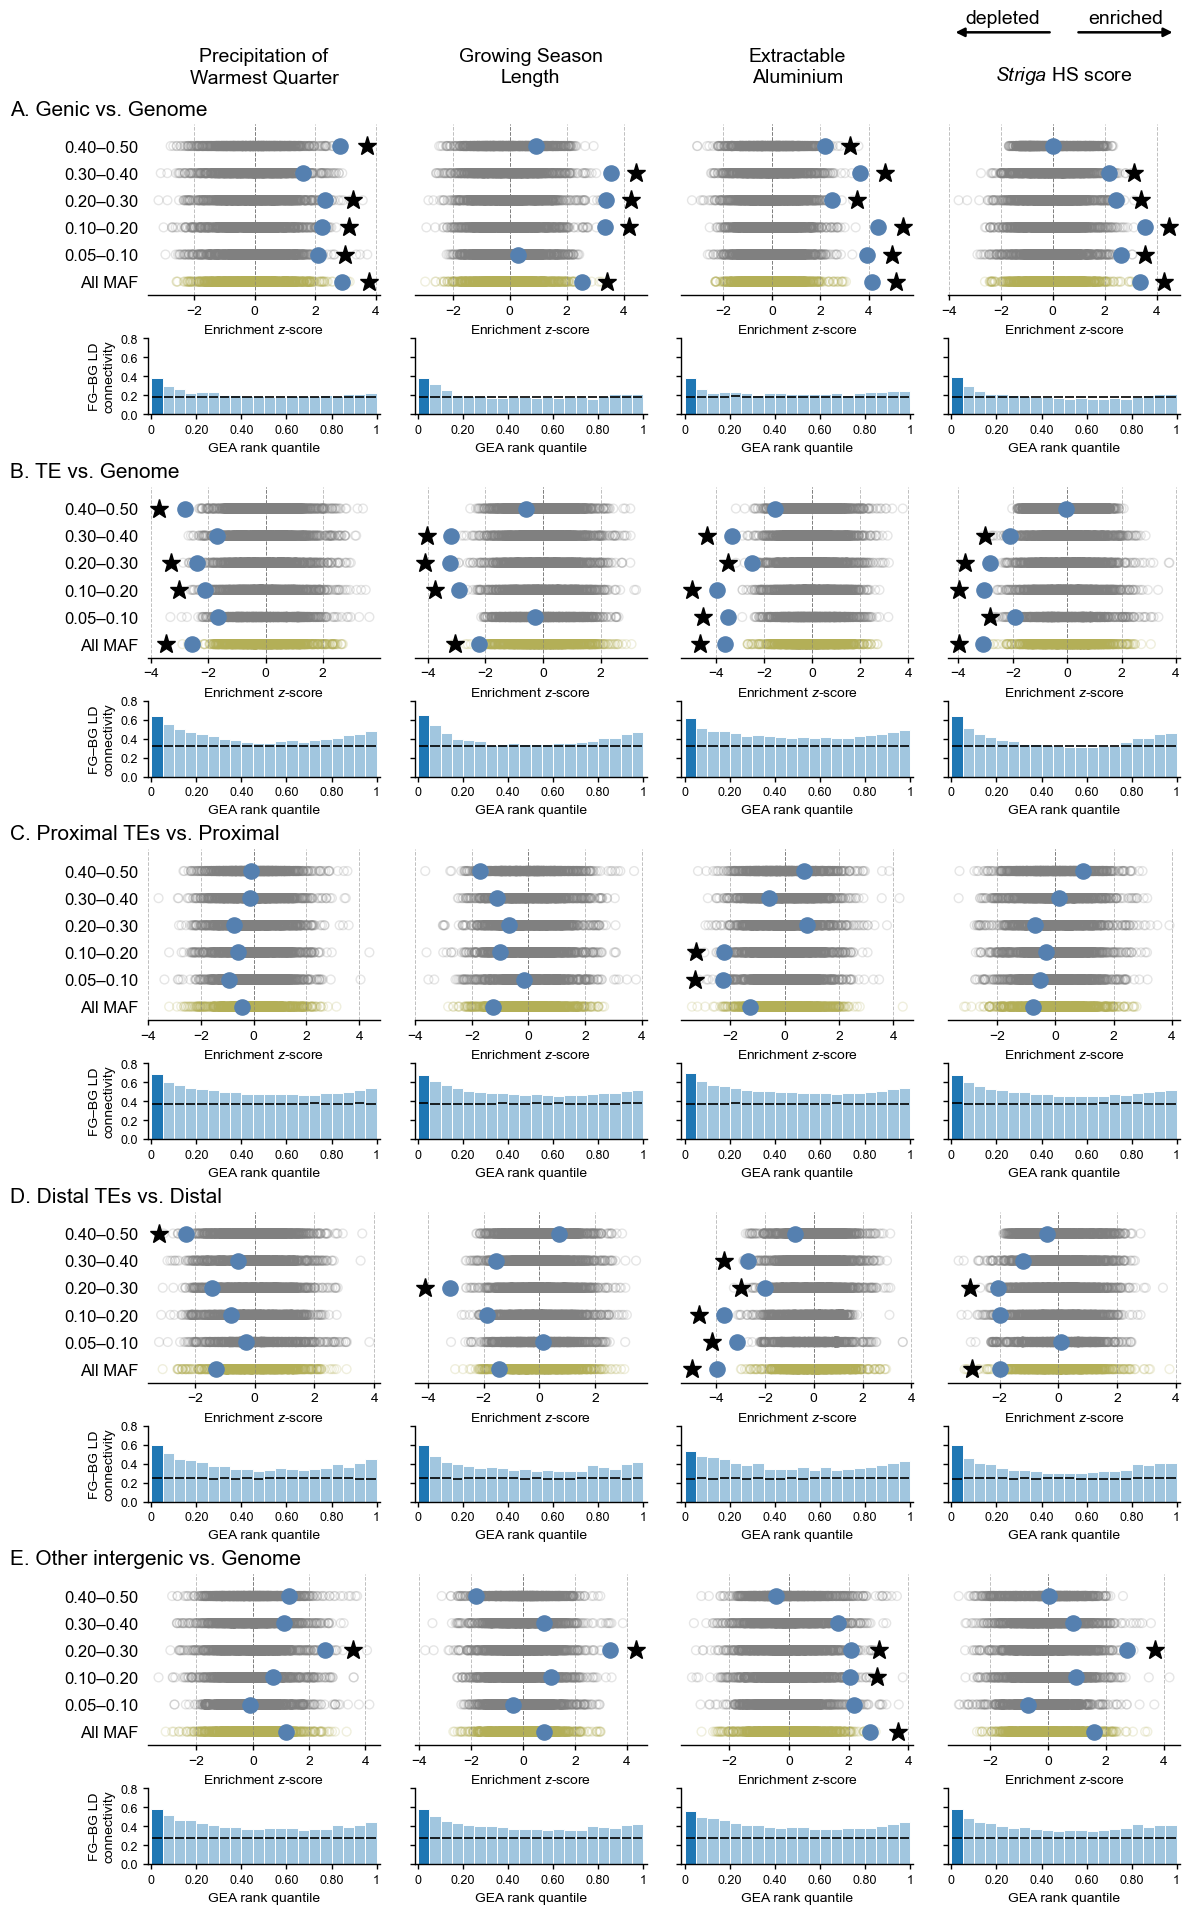

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/genomic_compartments.enrichment_and_overlap.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/genomic_compartments.enrichment_and_overlap.png', 'enrichment_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/genomic_compartments.enrichment_and_overlap.enrichment.csv.gz', 'ld_overlap_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/genomic_compartments.enrichment_and_overlap.ld_overlap.csv.gz'}


In [59]:
compartment_plot = plot_enrichment_section(
    compartment_result_files, contrast_label_map, env_id_list,
    env_metadata_df, stratify_label_map, figure_prefix,
    figsize=(12, 19), block_gap=0.25, section_title_fontsize=15,
    panel_params=dict(wspace=0.15, hspace=0.35),
    letter_labels=True, env_titles_first_only=True,
)
plt.show()
print(compartment_plot['files'])


**图 1. 不同基因组区室中的 GEA 富集。** 各组依次比较 Genic、TE、Proximal TE、Distal TE 和 Other intergenic 变异与相应背景。上方面板展示四个重点环境变量中不同 MAF 分层下的 GEA 富集。观测富集值（蓝色）与 1,000 次染色体内标签循环置换得到的零分布均以 Z-score 展示。置换值以灰色表示，合并 MAF 组以橄榄色表示。星号表示相对于零分布的显著差异（双侧经验 P <0.05）。下方面板展示前景与背景其余变异在对应的 5% 宽度 GEA 排名区间内的 LD 连通性。深蓝色柱表示前景与背景中各自 GEA 信号最强的 5% 变异之间的 LD 连通性，浅蓝色柱表示其余排名区间，黑色水平线段表示打乱 GEA 分数后得到的参照值。



### 1.2 基因结构

比较上游 2 kb、5′ UTR、CDS、内含子、3′ UTR 和下游 2 kb 区域中的 GEA 信号，基因结构依据最长的注释转录本及基因方向定义。

使用 Genic（基因本体及两侧各 2 kb）和 Genome（MAF ≥0.05 的全基因组变异）两种背景，各结构类别与相应背景中的其余变异比较。



In [60]:
structure_labels = [
    ('upstream_2kb', 'Upstream 2 kb'),
    ('five_prime_UTR', '5′ UTR'),
    ('CDS', 'CDS'),
    ('intron', 'Intron'),
    ('three_prime_UTR', '3′ UTR'),
    ('downstream_2kb', 'Downstream 2 kb'),
]
structure_contrast_labels = {
    background: [(f'{context_id}_vs_{background}', f'{label} vs. {background.capitalize()}')
                 for context_id, label in structure_labels]
    for background in ['genic', 'genome']
}
structure_result_files = {
    contrast_id: {
        'enrichment': f'{la_enrich_dir}/{contrast_id}.enrichment.json.gz',
        'overlap': f'{la_enrich_dir}/{contrast_id}_overlap_results.pkl',
    }
    for labels in structure_contrast_labels.values()
    for contrast_id, _ in labels
}
structure_figure_prefix = f'{la_enrich_dir}/gene_structure'
plot_params = dict(
    figsize=(12, 22.8), block_gap=0.25, section_title_fontsize=15,
    panel_params=dict(wspace=0.15, hspace=0.35),
    letter_labels=True, env_titles_first_only=True,
)


#### 1.2.1 Genic 背景

将各结构类别与 Genic 中的其余变异比较，考察基因相关区域内部的关联强度差异。



In [61]:
stage_start = perf_counter()
for contrast_id, label in tqdm(structure_contrast_labels['genic'], desc='Gene structure: Genic'):
    contrast = contrasts_settings[contrast_id]
    context_df = datasets[contrast['dataset']]
    site_contrast_runner(
        contrast_id, contrast, context_df, env_id_list, la_enrich_dir,
        permutations=permutations, top_percent=top_percent, pool_num=pool_num,
        force_recompute=force_recompute,
    )
    calculate_contrast_ld_overlap(
        contrast_id, contrast, context_df, env_id_list, ld_dict[contrast['dataset']],
        la_enrich_dir, bin_width=bin_width, min_R2=min_r2, random_seed=random_seed,
        force_recompute=force_recompute,
    )
print(f'[{datetime.now():%H:%M:%S}] Genic comparisons ready ({perf_counter() - stage_start:.1f}s)')


Gene structure: Genic: 100%|██████████| 6/6 [00:00<00:00, 55.90it/s]

Enrichment results already exist for contrast upstream_2kb_vs_genic, skipping.
LD overlap results already exist for contrast upstream_2kb_vs_genic. Skipping calculation.
Enrichment results already exist for contrast five_prime_UTR_vs_genic, skipping.
LD overlap results already exist for contrast five_prime_UTR_vs_genic. Skipping calculation.
Enrichment results already exist for contrast CDS_vs_genic, skipping.
LD overlap results already exist for contrast CDS_vs_genic. Skipping calculation.
Enrichment results already exist for contrast intron_vs_genic, skipping.
LD overlap results already exist for contrast intron_vs_genic. Skipping calculation.
Enrichment results already exist for contrast three_prime_UTR_vs_genic, skipping.
LD overlap results already exist for contrast three_prime_UTR_vs_genic. Skipping calculation.
Enrichment results already exist for contrast downstream_2kb_vs_genic, skipping.
LD overlap results already exist for contrast downstream_2kb_vs_genic. Skipping calculati

展示 Genic 背景中的基因结构富集



2026-10-15 01:47:23 Plotting 6 enrichment contrasts


Enrichment panels: 100%|██████████| 6/6 [00:03<00:00,  1.82it/s]


2026-10-15 01:47:42 Saved /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/gene_structure.genic.enrichment_and_overlap


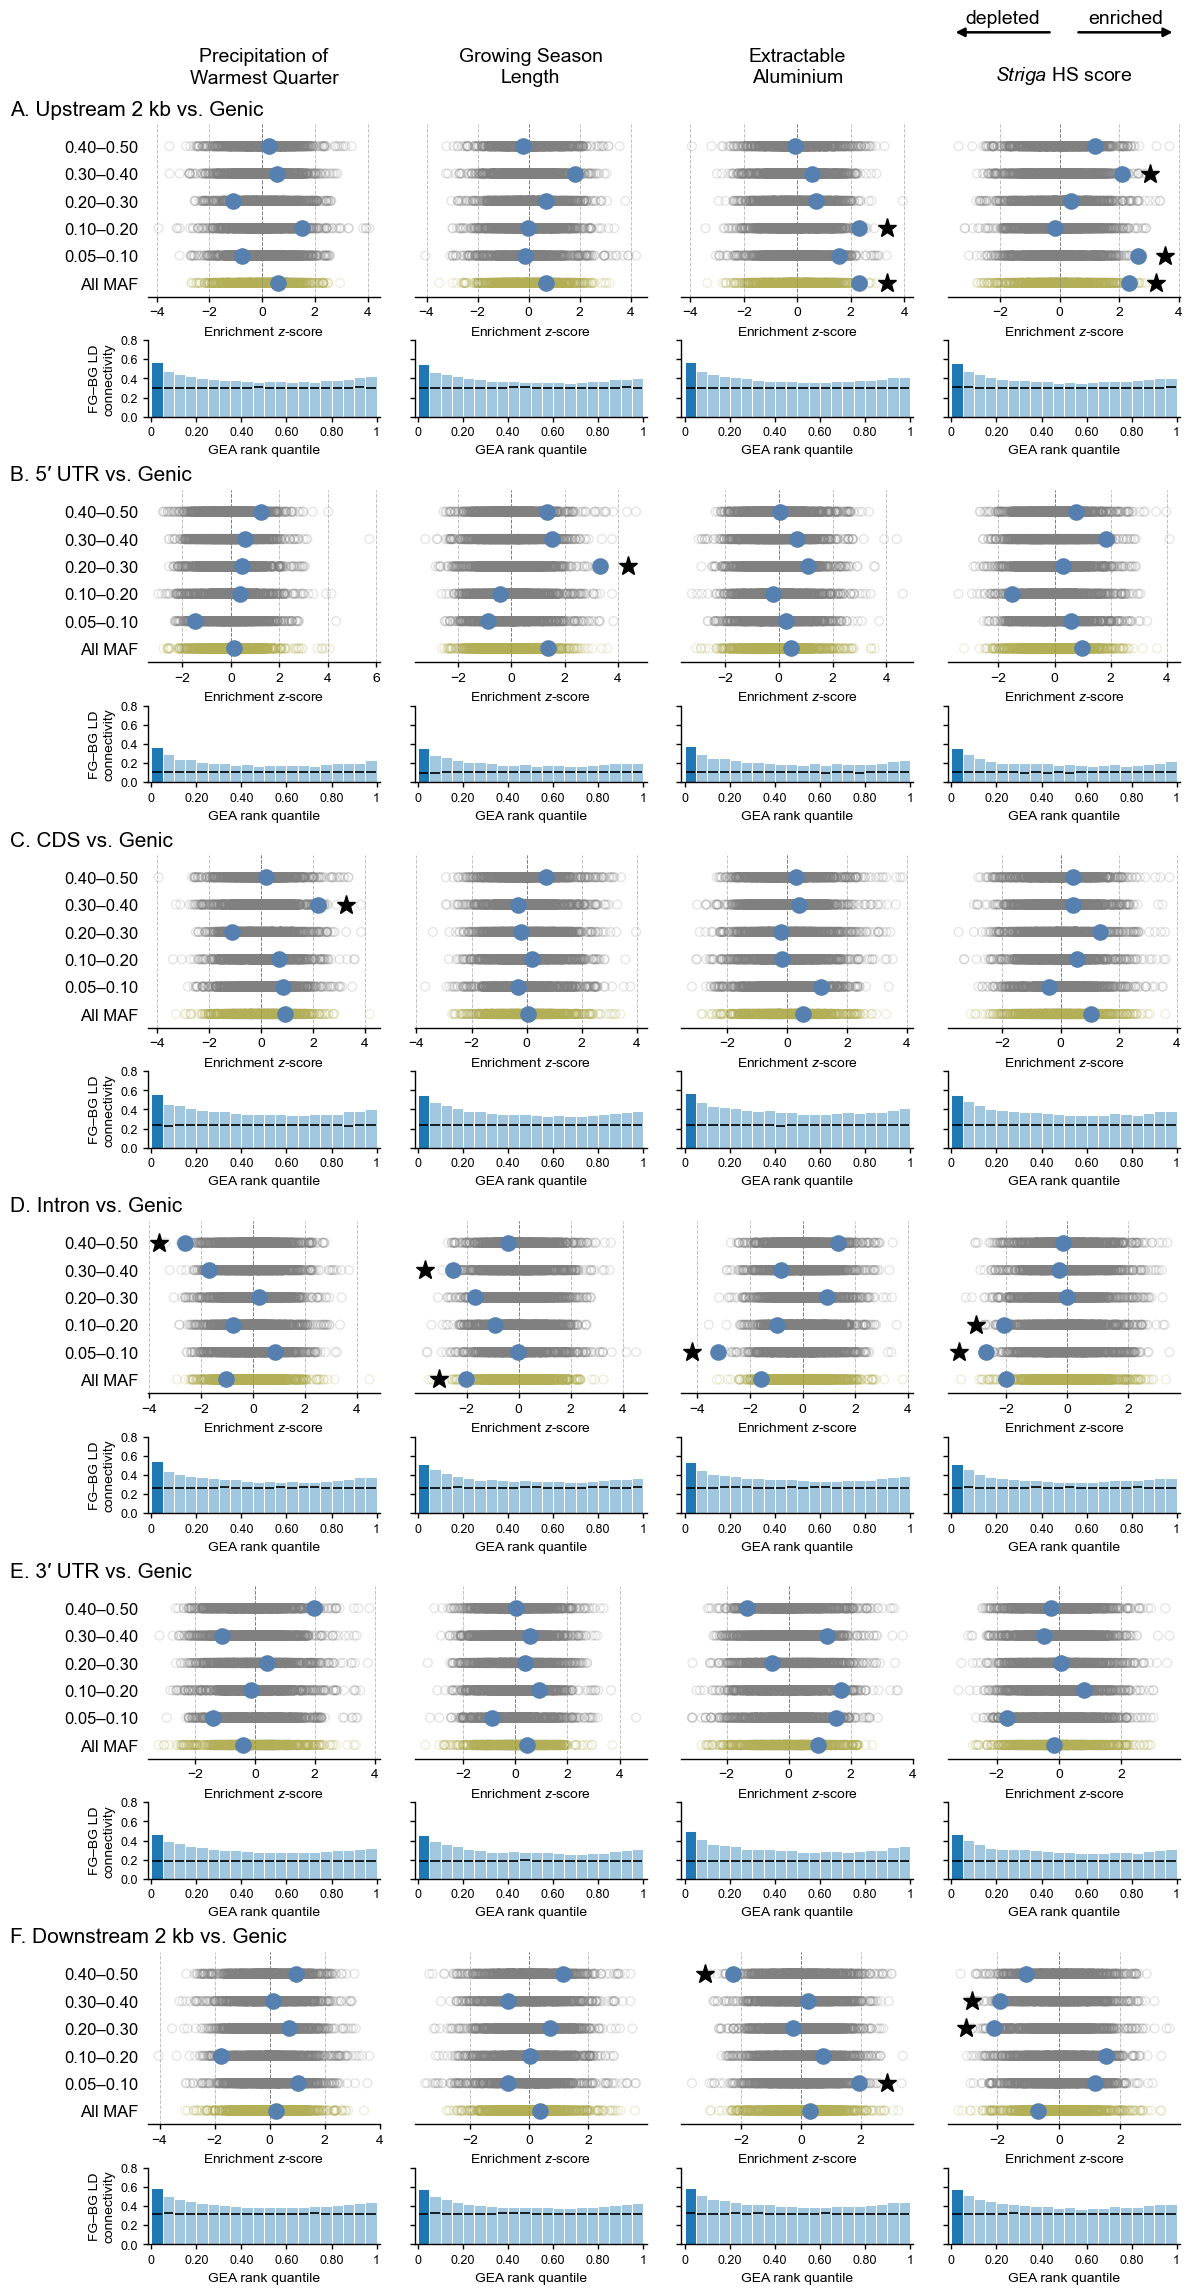

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/gene_structure.genic.enrichment_and_overlap.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/gene_structure.genic.enrichment_and_overlap.png', 'enrichment_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/gene_structure.genic.enrichment_and_overlap.enrichment.csv.gz', 'ld_overlap_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/gene_structure.genic.enrichment_and_overlap.ld_overlap.csv.gz'}


In [62]:
genic_structure_plot = plot_enrichment_section(
    structure_result_files, structure_contrast_labels['genic'], env_id_list,
    env_metadata_df, stratify_label_map,
    f'{structure_figure_prefix}.genic.enrichment_and_overlap', **plot_params,
)
plt.show()
print(genic_structure_plot['files'])


**图 2. Genic 背景中不同基因结构的 GEA 富集。** 各组依次比较上游 2 kb、5′ UTR、CDS、内含子、3′ UTR 和下游 2 kb 变异与 Genic 中的其余变异。上方面板展示四个重点环境变量中不同 MAF 分层下的 GEA 富集。观测富集值（蓝色）与 1,000 次染色体内标签循环置换得到的零分布均以 Z-score 展示。置换值以灰色表示，合并 MAF 组以橄榄色表示。星号表示相对于零分布的显著差异（双侧经验 P <0.05）。下方面板展示前景与背景其余变异在对应的 5% 宽度 GEA 排名区间内的 LD 连通性。深蓝色柱表示前景与背景中各自 GEA 信号最强的 5% 变异之间的 LD 连通性，浅蓝色柱表示其余排名区间，黑色水平线段表示打乱 GEA 分数后得到的参照值。



#### 1.2.2 Genome 背景

将相同结构类别与全基因组中的其余变异比较。



In [63]:
stage_start = perf_counter()
for contrast_id, label in tqdm(structure_contrast_labels['genome'], desc='Gene structure: Genome'):
    contrast = contrasts_settings[contrast_id]
    context_df = datasets[contrast['dataset']]
    site_contrast_runner(
        contrast_id, contrast, context_df, env_id_list, la_enrich_dir,
        permutations=permutations, top_percent=top_percent, pool_num=pool_num,
        force_recompute=force_recompute,
    )
    calculate_contrast_ld_overlap(
        contrast_id, contrast, context_df, env_id_list, ld_dict[contrast['dataset']],
        la_enrich_dir, bin_width=bin_width, min_R2=min_r2, random_seed=random_seed,
        force_recompute=force_recompute,
    )
print(f'[{datetime.now():%H:%M:%S}] Genome comparisons ready ({perf_counter() - stage_start:.1f}s)')


Gene structure: Genome: 100%|██████████| 6/6 [00:00<00:00, 53.84it/s]

Enrichment results already exist for contrast upstream_2kb_vs_genome, skipping.
LD overlap results already exist for contrast upstream_2kb_vs_genome. Skipping calculation.
Enrichment results already exist for contrast five_prime_UTR_vs_genome, skipping.
LD overlap results already exist for contrast five_prime_UTR_vs_genome. Skipping calculation.
Enrichment results already exist for contrast CDS_vs_genome, skipping.
LD overlap results already exist for contrast CDS_vs_genome. Skipping calculation.
Enrichment results already exist for contrast intron_vs_genome, skipping.
LD overlap results already exist for contrast intron_vs_genome. Skipping calculation.
Enrichment results already exist for contrast three_prime_UTR_vs_genome, skipping.
LD overlap results already exist for contrast three_prime_UTR_vs_genome. Skipping calculation.
Enrichment results already exist for contrast downstream_2kb_vs_genome, skipping.
LD overlap results already exist for contrast downstream_2kb_vs_genome. Skippi

展示 Genome 背景中的基因结构富集



2026-10-15 01:47:51 Plotting 6 enrichment contrasts


Enrichment panels: 100%|██████████| 6/6 [00:02<00:00,  2.87it/s]


2026-10-15 01:48:09 Saved /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/gene_structure.genome.enrichment_and_overlap


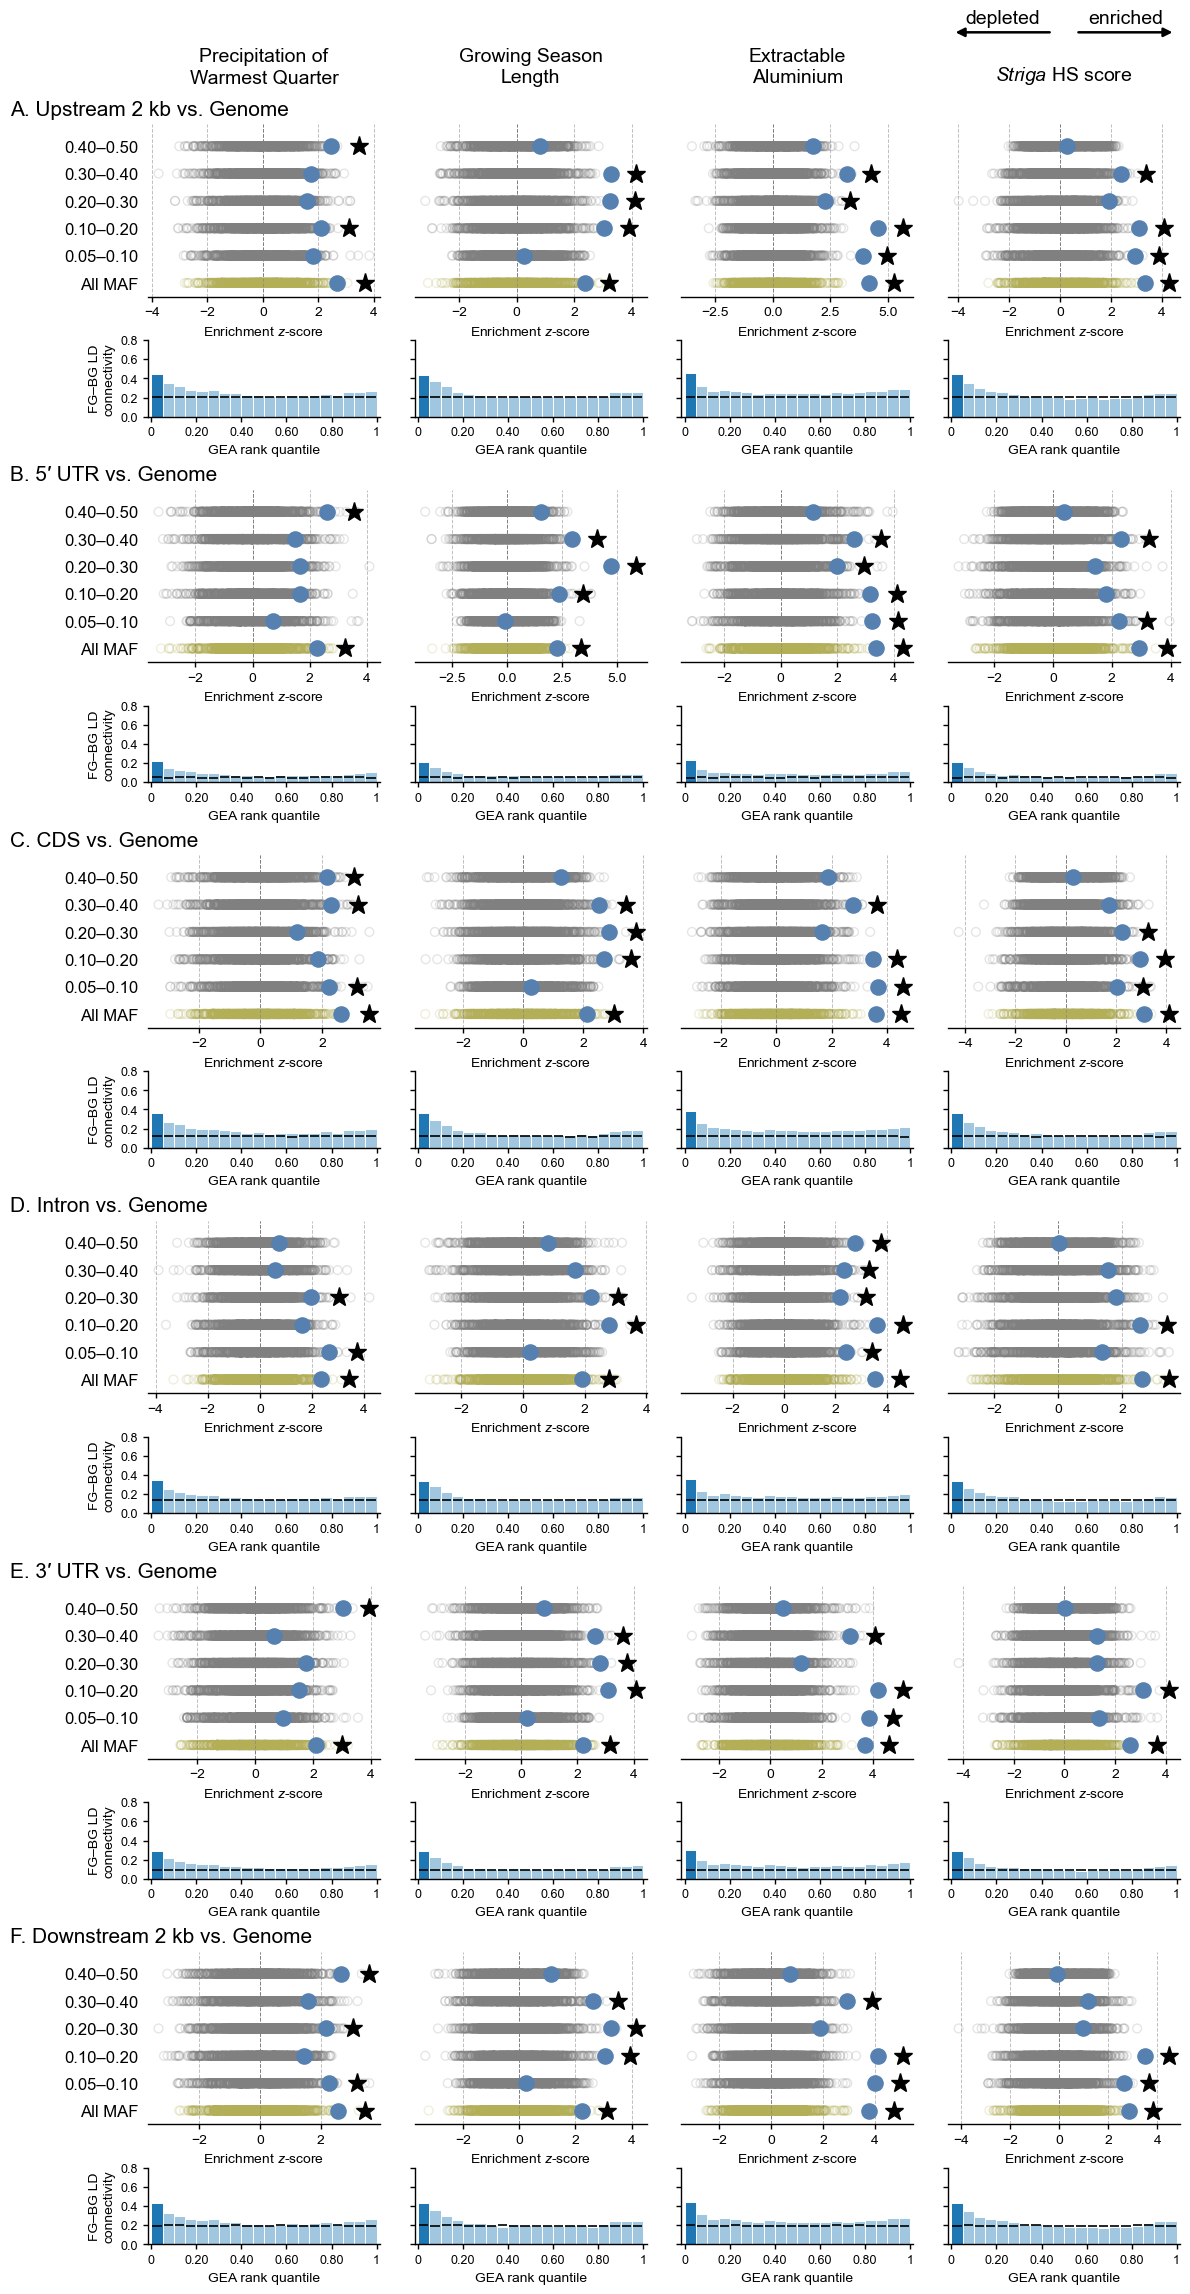

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/gene_structure.genome.enrichment_and_overlap.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/gene_structure.genome.enrichment_and_overlap.png', 'enrichment_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/gene_structure.genome.enrichment_and_overlap.enrichment.csv.gz', 'ld_overlap_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/gene_structure.genome.enrichment_and_overlap.ld_overlap.csv.gz'}


In [64]:
genome_structure_plot = plot_enrichment_section(
    structure_result_files, structure_contrast_labels['genome'], env_id_list,
    env_metadata_df, stratify_label_map,
    f'{structure_figure_prefix}.genome.enrichment_and_overlap', **plot_params,
)
plt.show()
print(genome_structure_plot['files'])


**图 3. 全基因组背景中不同基因结构的 GEA 富集。** 各组依次比较上游 2 kb、5′ UTR、CDS、内含子、3′ UTR 和下游 2 kb 变异与全基因组中的其余变异。上方面板展示四个重点环境变量中不同 MAF 分层下的 GEA 富集。观测富集值（蓝色）与 1,000 次染色体内标签循环置换得到的零分布均以 Z-score 展示。置换值以灰色表示，合并 MAF 组以橄榄色表示。星号表示相对于零分布的显著差异（双侧经验 P <0.05）。下方面板展示前景与背景其余变异在对应的 5% 宽度 GEA 排名区间内的 LD 连通性。深蓝色柱表示前景与背景中各自 GEA 信号最强的 5% 变异之间的 LD 连通性，浅蓝色柱表示其余排名区间，黑色水平线段表示打乱 GEA 分数后得到的参照值。



### 1.3 编码变异

依据 SnpEff 后果注释，比较错义、同义和候选功能缺失（putative LoF）变异，使用 MAF ≥0.01、杂合率 ≤0.05 的 CDS 变异。先将各后果类别与其余 CDS 变异比较，再考察候选 LoF 集合内部两个较低频率类别的差异。



In [65]:
coding_contrast_labels = [
    ('missense_vs_CDS', 'Missense vs. CDS'),
    ('synonymous_vs_CDS', 'Synonymous vs. CDS'),
    ('putative_LoF_vs_CDS', 'Putative LoF vs. CDS'),
]
lof_contrast_id = 'putative_LoF_MAF_0.01_0.03_vs_putative_LoF_MAF_0.03_0.05'
lof_contrast_labels = [(lof_contrast_id, 'Putative LoF: MAF 0.01–0.03 vs. 0.03–0.05')]
coding_result_files = {
    contrast_id: {
        'enrichment': f'{la_enrich_dir}/{contrast_id}.enrichment.json.gz',
        'overlap': f'{la_enrich_dir}/{contrast_id}_overlap_results.pkl',
    }
    for contrast_id, _ in coding_contrast_labels + lof_contrast_labels
}
cds_stratify_label_map = [
    ['all', 'All MAF'],
    ['maf_0.01_0.03_cds_0.01', '0.01–0.03'],
    ['maf_0.03_0.05_cds_0.01', '0.03–0.05'],
    ['maf_0.05_0.1_cds_0.01', '0.05–0.10'],
    ['maf_0.1_0.2_cds_0.01', '0.10–0.20'],
    ['maf_0.2_0.3_cds_0.01', '0.20–0.30'],
    ['maf_0.3_0.4_cds_0.01', '0.30–0.40'],
    ['maf_0.4_0.5_cds_0.01', '0.40–0.50'],
]
coding_figure_prefix = f'{la_enrich_dir}/coding_mutations'
plot_params = dict(
    figsize=(12, 13.2), block_gap=0.25, section_title_fontsize=15,
    panel_params=dict(wspace=0.15, hspace=0.35, height_ratios=(3, 1)),
    letter_labels=True, env_titles_first_only=True,
)


#### 1.3.1 CDS 背景中的编码后果

将各后果类别与其余 CDS 变异比较，分别分析全部保留变异和七个 MAF 类别，包括 0.01–0.03 和 0.03–0.05。



In [66]:
stage_start = perf_counter()
for contrast_id, label in tqdm(coding_contrast_labels, desc='Coding consequences'):
    contrast = contrasts_settings[contrast_id]
    context_df = datasets[contrast['dataset']]
    site_contrast_runner(
        contrast_id, contrast, context_df, env_id_list, la_enrich_dir,
        permutations=permutations, top_percent=top_percent, pool_num=pool_num,
        force_recompute=force_recompute,
    )
    calculate_contrast_ld_overlap(
        contrast_id, contrast, context_df, env_id_list, ld_dict[contrast['dataset']],
        la_enrich_dir, bin_width=bin_width, min_R2=min_r2, random_seed=random_seed,
        force_recompute=force_recompute,
    )
print(f'[{datetime.now():%H:%M:%S}] Coding-consequence results ready ({perf_counter() - stage_start:.1f}s)')


Coding consequences: 100%|██████████| 3/3 [00:00<00:00, 43.79it/s]

Enrichment results already exist for contrast missense_vs_CDS, skipping.
LD overlap results already exist for contrast missense_vs_CDS. Skipping calculation.
Enrichment results already exist for contrast synonymous_vs_CDS, skipping.
LD overlap results already exist for contrast synonymous_vs_CDS. Skipping calculation.
Enrichment results already exist for contrast putative_LoF_vs_CDS, skipping.
LD overlap results already exist for contrast putative_LoF_vs_CDS. Skipping calculation.
[01:48:17] Coding-consequence results ready (0.1s)


展示编码后果富集



2026-10-15 01:48:18 Plotting 3 enrichment contrasts


Enrichment panels: 100%|██████████| 3/3 [00:01<00:00,  2.70it/s]


2026-10-15 01:48:29 Saved /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/coding_mutations.consequences.enrichment_and_overlap


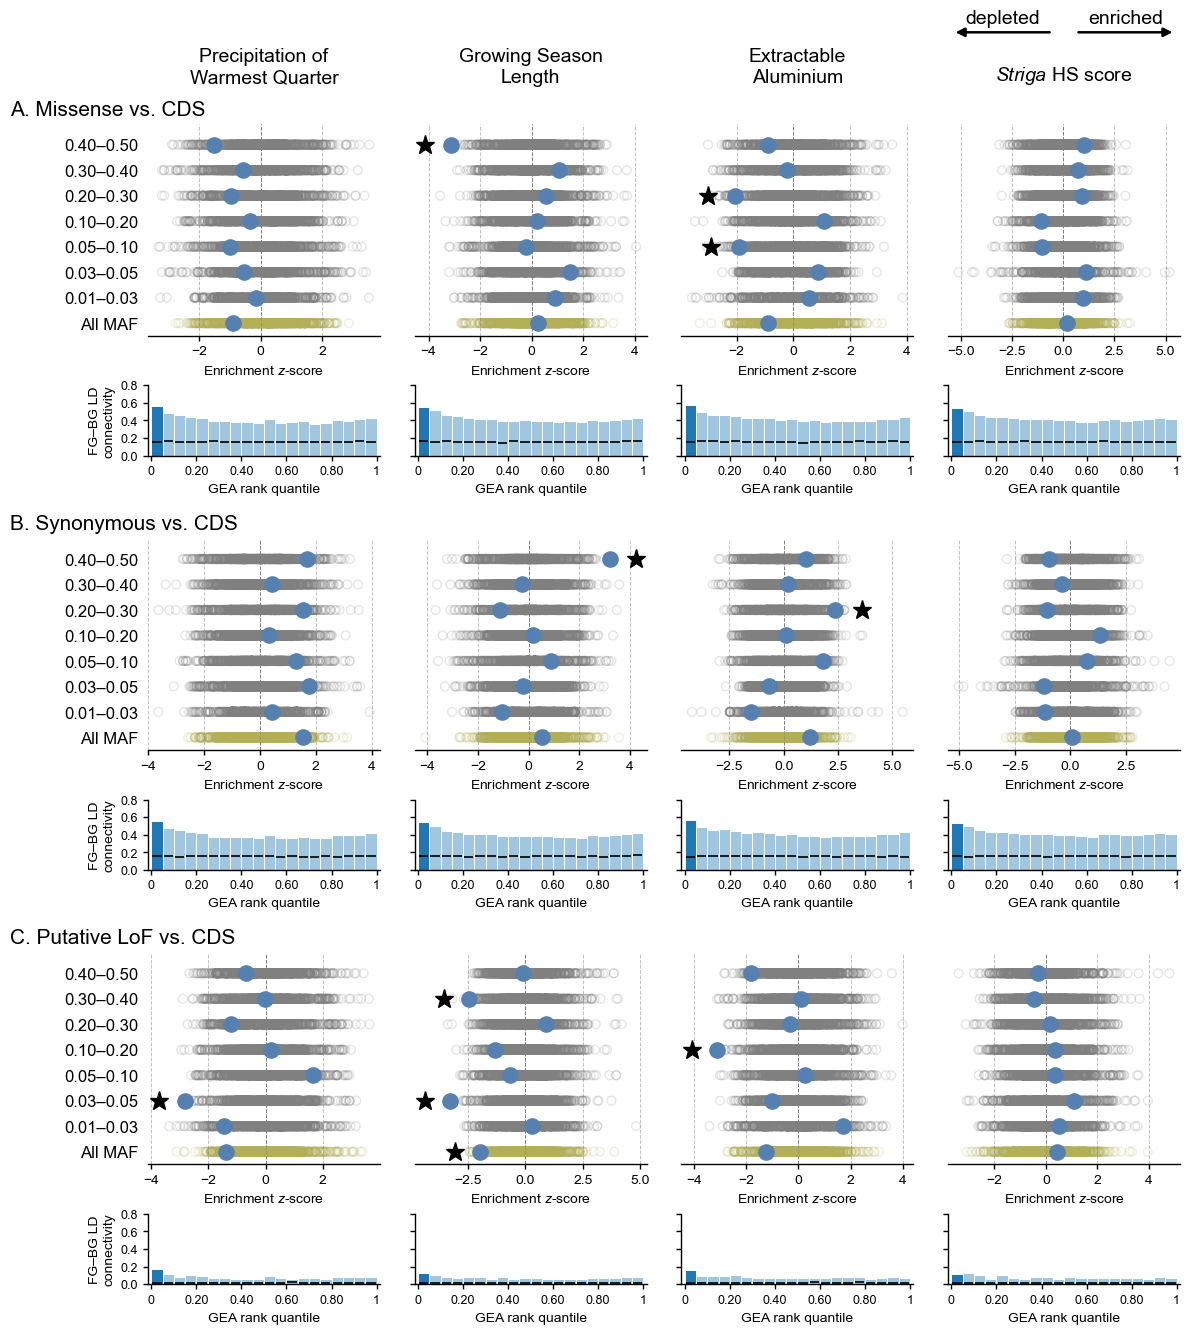

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/coding_mutations.consequences.enrichment_and_overlap.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/coding_mutations.consequences.enrichment_and_overlap.png', 'enrichment_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/coding_mutations.consequences.enrichment_and_overlap.enrichment.csv.gz', 'ld_overlap_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/coding_mutations.consequences.enrichment_and_overlap.ld_overlap.csv.gz'}


In [67]:
coding_plot = plot_enrichment_section(
    coding_result_files, coding_contrast_labels, env_id_list,
    env_metadata_df, cds_stratify_label_map,
    f'{coding_figure_prefix}.consequences.enrichment_and_overlap', **plot_params,
)
plt.show()
print(coding_plot['files'])


**图 4. 不同编码后果类别中的 GEA 富集。** 各组依次比较错义、同义和候选 LoF 变异与其余 CDS 变异。上方面板展示四个重点环境变量中不同 MAF 分层下的 GEA 富集。观测富集值（蓝色）与 1,000 次染色体内标签循环置换得到的零分布均以 Z-score 展示。置换值以灰色表示，合并 MAF 组以橄榄色表示。星号表示相对于零分布的显著差异（双侧经验 P <0.05）。下方面板展示前景与背景其余变异在对应的 5% 宽度 GEA 排名区间内的 LD 连通性。深蓝色柱表示前景与背景中各自 GEA 信号最强的 5% 变异之间的 LD 连通性，浅蓝色柱表示其余排名区间，黑色水平线段表示打乱 GEA 分数后得到的参照值。



#### 1.3.2 不同频率候选 LoF 变异的 GEA 信号

以 0.03 ≤MAF <0.05 的候选 LoF 变异为背景，比较 0.01 ≤MAF <0.03 的候选 LoF 变异，不再额外进行 MAF 分层。



In [68]:
stage_start = perf_counter()
contrast = dict(contrasts_settings[lof_contrast_id])
contrast['maf_stratify'] = ['all']
context_df = datasets[contrast['dataset']]
site_contrast_runner(
    lof_contrast_id, contrast, context_df, env_id_list, la_enrich_dir,
    permutations=permutations, top_percent=top_percent, pool_num=pool_num,
    force_recompute=force_recompute,
)
calculate_contrast_ld_overlap(
    lof_contrast_id, contrast, context_df, env_id_list, ld_dict[contrast['dataset']],
    la_enrich_dir, bin_width=bin_width, min_R2=min_r2, random_seed=random_seed,
    force_recompute=force_recompute,
)
print(f'[{datetime.now():%H:%M:%S}] LoF frequency comparison ready ({perf_counter() - stage_start:.1f}s)')


Enrichment results already exist for contrast putative_LoF_MAF_0.01_0.03_vs_putative_LoF_MAF_0.03_0.05, skipping.
LD overlap results already exist for contrast putative_LoF_MAF_0.01_0.03_vs_putative_LoF_MAF_0.03_0.05. Skipping calculation.
[01:48:37] LoF frequency comparison ready (0.0s)


展示候选 LoF 频率对比



2026-10-15 01:48:38 Plotting 1 enrichment contrasts


Enrichment panels: 100%|██████████| 1/1 [00:00<00:00,  4.87it/s]


2026-10-15 01:48:39 Saved /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/coding_mutations.lof_frequency.enrichment_and_overlap


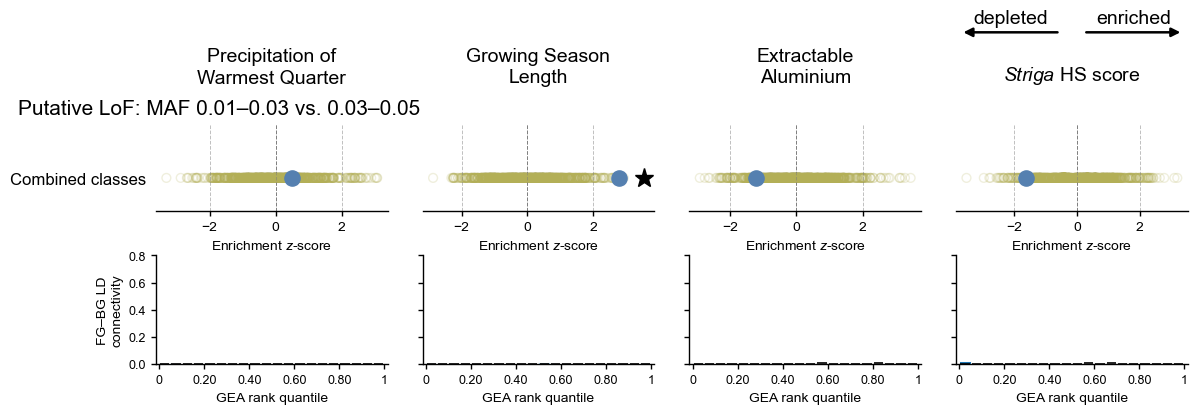

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/coding_mutations.lof_frequency.enrichment_and_overlap.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/coding_mutations.lof_frequency.enrichment_and_overlap.png', 'enrichment_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/coding_mutations.lof_frequency.enrichment_and_overlap.enrichment.csv.gz', 'ld_overlap_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/coding_mutations.lof_frequency.enrichment_and_overlap.ld_overlap.csv.gz'}


In [69]:
lof_frequency_plot = plot_enrichment_section(
    coding_result_files, lof_contrast_labels, env_id_list,
    env_metadata_df, [['all', 'Combined classes']],
    f'{coding_figure_prefix}.lof_frequency.enrichment_and_overlap',
    figsize=(12, 4.0), section_title_fontsize=15,
    panel_params=dict(wspace=0.15, hspace=0.45, height_ratios=(0.8, 1)),
    letter_labels=True, env_titles_first_only=True,
)
plt.show()
print(lof_frequency_plot['files'])


**图 5. 不同频率候选 LoF 变异中的 GEA 富集。** 前景为 0.01 ≤MAF <0.03 的候选 LoF 变异，背景为 0.03 ≤MAF <0.05 的候选 LoF 变异，展示两类合并后的结果。上方面板展示四个重点环境变量中的 GEA 富集。观测富集值（蓝色）与 1,000 次染色体内标签循环置换得到的零分布均以 Z-score 展示。置换值以灰色表示，合并 MAF 组以橄榄色表示。星号表示相对于零分布的显著差异（双侧经验 P <0.05）。下方面板展示前景与背景其余变异在对应的 5% 宽度 GEA 排名区间内的 LD 连通性。深蓝色柱表示前景与背景中各自 GEA 信号最强的 5% 变异之间的 LD 连通性，浅蓝色柱表示其余排名区间，黑色水平线段表示打乱 GEA 分数后得到的参照值。



### 1.4 表观基因组特征

在 Genome 背景及 Proximal、Distal 区域内，比较开放染色质区域（ACR）和未甲基化区域（UMR）中的 GEA 信号。Proximal 包括基因本体及两侧各 5 kb，Distal 为该范围之外的区域。使用 MAF ≥0.05 的全基因组变异，将各类注释与相应背景中的其余变异比较。



In [70]:
epigenomic_contrast_labels = {
    'ACRs': [
        ('ACR_vs_genome', 'ACRs vs. Genome'),
        ('proximal_ACR_vs_proximal', 'Proximal ACRs vs. Proximal'),
        ('distal_ACR_vs_distal', 'Distal ACRs vs. Distal'),
    ],
    'UMRs': [
        ('UMR_vs_genome', 'UMRs vs. Genome'),
        ('proximal_UMR_vs_proximal', 'Proximal UMRs vs. Proximal'),
        ('distal_UMR_vs_distal', 'Distal UMRs vs. Distal'),
    ],
}
epigenomic_result_files = {
    contrast_id: {
        'enrichment': f'{la_enrich_dir}/{contrast_id}.enrichment.json.gz',
        'overlap': f'{la_enrich_dir}/{contrast_id}_overlap_results.pkl',
    }
    for labels in epigenomic_contrast_labels.values()
    for contrast_id, _ in labels
}
epigenomic_figure_prefix = f'{la_enrich_dir}/epigenomic_features'
plot_params = dict(
    figsize=(12, 11.4), block_gap=0.25, section_title_fontsize=15,
    panel_params=dict(wspace=0.15, hspace=0.35),
    letter_labels=True, env_titles_first_only=True,
)


#### 1.4.1 开放染色质区域（ACR）

将 ACR 内的变异分别与 Genome、Proximal 和 Distal 背景中的其余变异比较。



In [71]:
stage_start = perf_counter()
for contrast_id, label in tqdm(epigenomic_contrast_labels['ACRs'], desc='ACRs enrichment'):
    contrast = contrasts_settings[contrast_id]
    context_df = datasets[contrast['dataset']]
    site_contrast_runner(
        contrast_id, contrast, context_df, env_id_list, la_enrich_dir,
        permutations=permutations, top_percent=top_percent, pool_num=pool_num,
        force_recompute=force_recompute,
    )
    calculate_contrast_ld_overlap(
        contrast_id, contrast, context_df, env_id_list, ld_dict[contrast['dataset']],
        la_enrich_dir, bin_width=bin_width, min_R2=min_r2, random_seed=random_seed,
        force_recompute=force_recompute,
    )
print(f'[{datetime.now():%H:%M:%S}] ACRs comparisons ready ({perf_counter() - stage_start:.1f}s)')


ACRs enrichment: 100%|██████████| 3/3 [00:00<00:00, 48.02it/s]

Enrichment results already exist for contrast ACR_vs_genome, skipping.
LD overlap results already exist for contrast ACR_vs_genome. Skipping calculation.
Enrichment results already exist for contrast proximal_ACR_vs_proximal, skipping.
LD overlap results already exist for contrast proximal_ACR_vs_proximal. Skipping calculation.
Enrichment results already exist for contrast distal_ACR_vs_distal, skipping.
LD overlap results already exist for contrast distal_ACR_vs_distal. Skipping calculation.
[01:48:41] ACRs comparisons ready (0.1s)


展示 ACR 富集



2026-10-15 01:48:41 Plotting 3 enrichment contrasts


Enrichment panels: 100%|██████████| 3/3 [00:00<00:00,  3.72it/s]


2026-10-15 01:48:49 Saved /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/epigenomic_features.acrs.enrichment_and_overlap


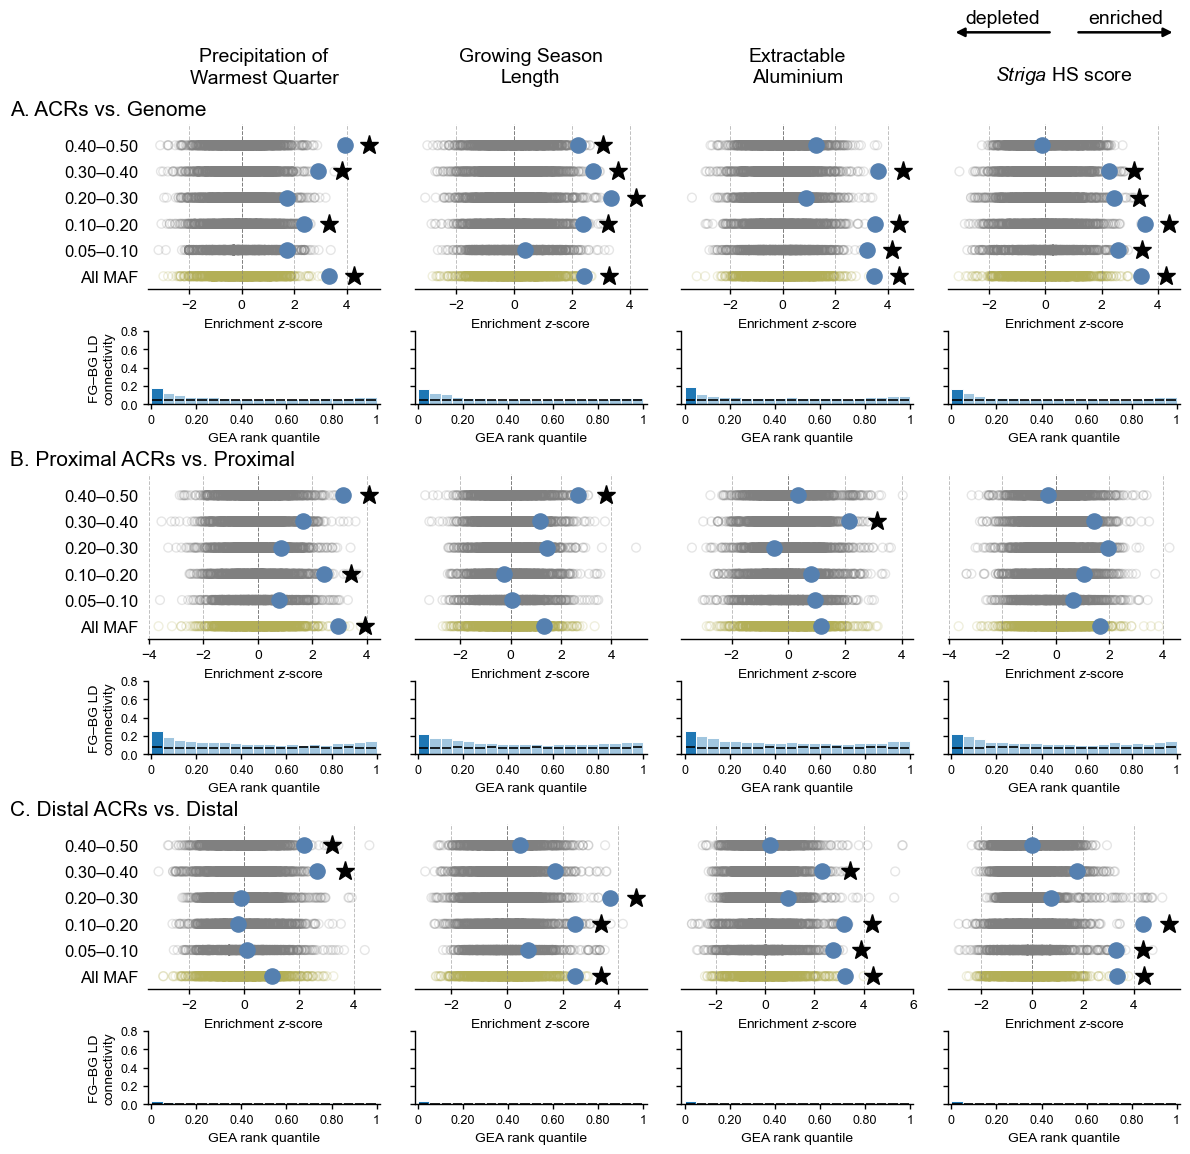

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/epigenomic_features.acrs.enrichment_and_overlap.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/epigenomic_features.acrs.enrichment_and_overlap.png', 'enrichment_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/epigenomic_features.acrs.enrichment_and_overlap.enrichment.csv.gz', 'ld_overlap_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/epigenomic_features.acrs.enrichment_and_overlap.ld_overlap.csv.gz'}


In [72]:
acrs_plot = plot_enrichment_section(
    epigenomic_result_files, epigenomic_contrast_labels['ACRs'], env_id_list,
    env_metadata_df, stratify_label_map,
    f'{epigenomic_figure_prefix}.acrs.enrichment_and_overlap', **plot_params,
)
plt.show()
print(acrs_plot['files'])


**图 6. 开放染色质区域中的 GEA 富集。** 各组依次将 ACR 内的变异与 Genome、Proximal 和 Distal 背景中的其余变异比较。上方面板展示四个重点环境变量中不同 MAF 分层下的 GEA 富集。观测富集值（蓝色）与 1,000 次染色体内标签循环置换得到的零分布均以 Z-score 展示。置换值以灰色表示，合并 MAF 组以橄榄色表示。星号表示相对于零分布的显著差异（双侧经验 P <0.05）。下方面板展示前景与背景其余变异在对应的 5% 宽度 GEA 排名区间内的 LD 连通性。深蓝色柱表示前景与背景中各自 GEA 信号最强的 5% 变异之间的 LD 连通性，浅蓝色柱表示其余排名区间，黑色水平线段表示打乱 GEA 分数后得到的参照值。



#### 1.4.2 未甲基化区域（UMR）

对 UMR 内的变异采用相同的三种背景。



In [73]:
stage_start = perf_counter()
for contrast_id, label in tqdm(epigenomic_contrast_labels['UMRs'], desc='UMRs enrichment'):
    contrast = contrasts_settings[contrast_id]
    context_df = datasets[contrast['dataset']]
    site_contrast_runner(
        contrast_id, contrast, context_df, env_id_list, la_enrich_dir,
        permutations=permutations, top_percent=top_percent, pool_num=pool_num,
        force_recompute=force_recompute,
    )
    calculate_contrast_ld_overlap(
        contrast_id, contrast, context_df, env_id_list, ld_dict[contrast['dataset']],
        la_enrich_dir, bin_width=bin_width, min_R2=min_r2, random_seed=random_seed,
        force_recompute=force_recompute,
    )
print(f'[{datetime.now():%H:%M:%S}] UMRs comparisons ready ({perf_counter() - stage_start:.1f}s)')


UMRs enrichment: 100%|██████████| 3/3 [00:00<00:00, 45.35it/s]

Enrichment results already exist for contrast UMR_vs_genome, skipping.
LD overlap results already exist for contrast UMR_vs_genome. Skipping calculation.
Enrichment results already exist for contrast proximal_UMR_vs_proximal, skipping.
LD overlap results already exist for contrast proximal_UMR_vs_proximal. Skipping calculation.
Enrichment results already exist for contrast distal_UMR_vs_distal, skipping.
LD overlap results already exist for contrast distal_UMR_vs_distal. Skipping calculation.
[01:48:54] UMRs comparisons ready (0.1s)


展示 UMR 富集



2026-10-15 01:48:55 Plotting 3 enrichment contrasts


Enrichment panels: 100%|██████████| 3/3 [00:01<00:00,  2.99it/s]


2026-10-15 01:49:04 Saved /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/epigenomic_features.umrs.enrichment_and_overlap


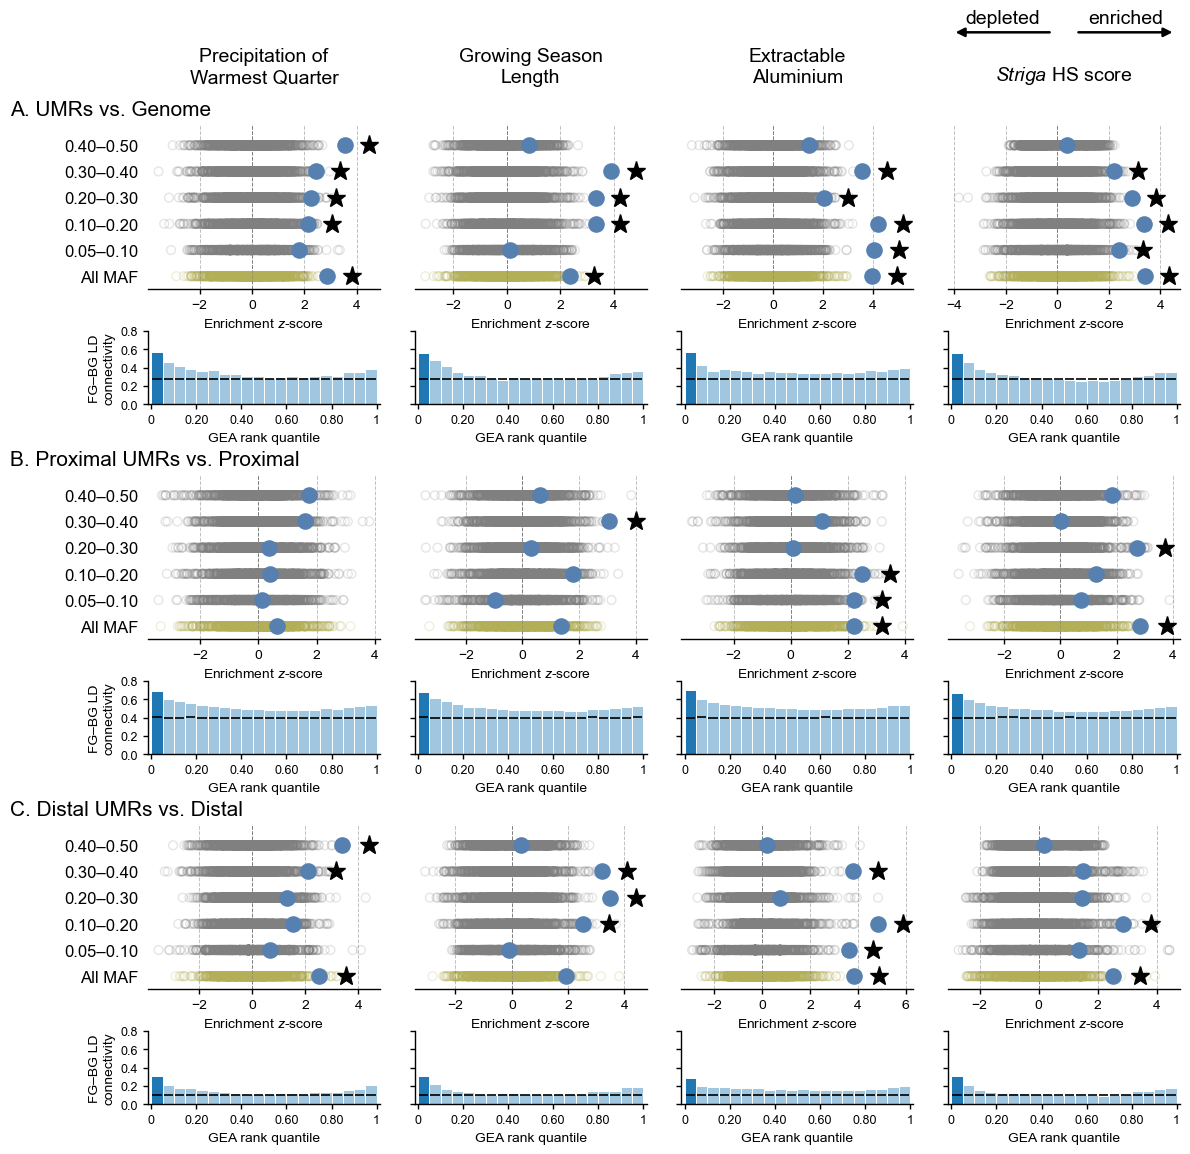

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/epigenomic_features.umrs.enrichment_and_overlap.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/epigenomic_features.umrs.enrichment_and_overlap.png', 'enrichment_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/epigenomic_features.umrs.enrichment_and_overlap.enrichment.csv.gz', 'ld_overlap_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/epigenomic_features.umrs.enrichment_and_overlap.ld_overlap.csv.gz'}


In [74]:
umrs_plot = plot_enrichment_section(
    epigenomic_result_files, epigenomic_contrast_labels['UMRs'], env_id_list,
    env_metadata_df, stratify_label_map,
    f'{epigenomic_figure_prefix}.umrs.enrichment_and_overlap', **plot_params,
)
plt.show()
print(umrs_plot['files'])


**图 7. 未甲基化区域中的 GEA 富集。** 各组依次将 UMR 内的变异与 Genome、Proximal 和 Distal 背景中的其余变异比较。上方面板展示四个重点环境变量中不同 MAF 分层下的 GEA 富集。观测富集值（蓝色）与 1,000 次染色体内标签循环置换得到的零分布均以 Z-score 展示。置换值以灰色表示，合并 MAF 组以橄榄色表示。星号表示相对于零分布的显著差异（双侧经验 P <0.05）。下方面板展示前景与背景其余变异在对应的 5% 宽度 GEA 排名区间内的 LD 连通性。深蓝色柱表示前景与背景中各自 GEA 信号最强的 5% 变异之间的 LD 连通性，浅蓝色柱表示其余排名区间，黑色水平线段表示打乱 GEA 分数后得到的参照值。



### 1.5 riboSNitches

使用 MAF ≥0.05 的全基因组变异，将预测的 riboSNitches 与其余基因本体变异比较，不额外增加侧翼。以 SNPfold CC_BPPROB <0.8 定义 riboSNitches，同一变异有多个预测时采用最低分值。

In [75]:
ribo_contrast_labels = [('riboSNitch_vs_gene_body', 'riboSNitches vs. Gene body')]
ribo_result_files = {
    contrast_id: {
        'enrichment': f'{la_enrich_dir}/{contrast_id}.enrichment.json.gz',
        'overlap': f'{la_enrich_dir}/{contrast_id}_overlap_results.pkl',
    }
    for contrast_id, _ in ribo_contrast_labels
}
ribo_figure_prefix = f'{la_enrich_dir}/ribosnitches.enrichment_and_overlap'


In [76]:
stage_start = perf_counter()
contrast_id = ribo_contrast_labels[0][0]
contrast = contrasts_settings[contrast_id]
context_df = datasets[contrast['dataset']]
site_contrast_runner(
    contrast_id, contrast, context_df, env_id_list, la_enrich_dir,
    permutations=permutations, top_percent=top_percent, pool_num=pool_num,
    force_recompute=force_recompute,
)
calculate_contrast_ld_overlap(
    contrast_id, contrast, context_df, env_id_list, ld_dict[contrast['dataset']],
    la_enrich_dir, bin_width=bin_width, min_R2=min_r2, random_seed=random_seed,
    force_recompute=force_recompute,
)
print(f'[{datetime.now():%H:%M:%S}] riboSNitch comparison ready ({perf_counter() - stage_start:.1f}s)')


Enrichment results already exist for contrast riboSNitch_vs_gene_body, skipping.
LD overlap results already exist for contrast riboSNitch_vs_gene_body. Skipping calculation.
[01:49:08] riboSNitch comparison ready (0.0s)


展示 riboSNitch 富集



2026-10-15 01:49:09 Plotting 1 enrichment contrasts


Enrichment panels: 100%|██████████| 1/1 [00:00<00:00,  3.00it/s]


2026-10-15 01:49:12 Saved /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/ribosnitches.enrichment_and_overlap


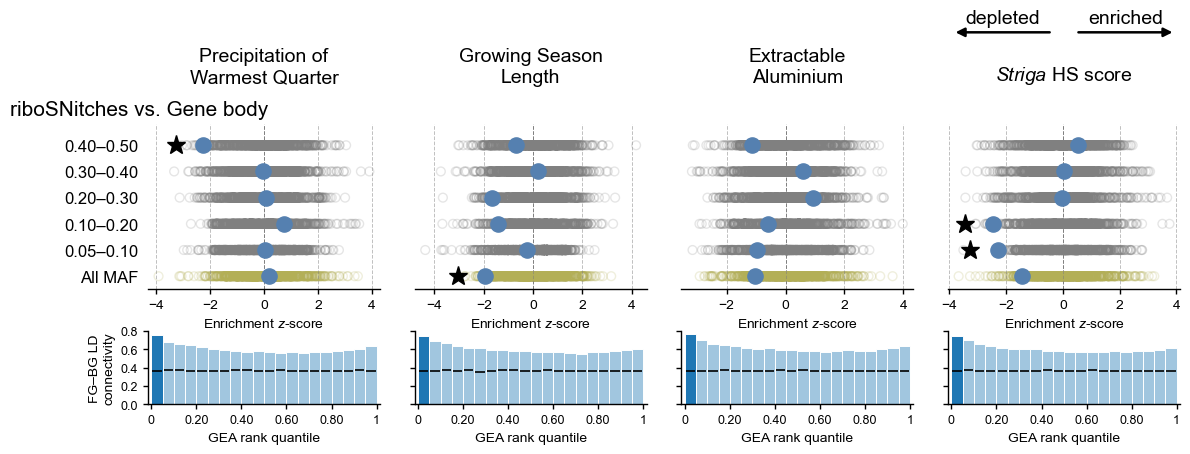

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/ribosnitches.enrichment_and_overlap.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/ribosnitches.enrichment_and_overlap.png', 'enrichment_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/ribosnitches.enrichment_and_overlap.enrichment.csv.gz', 'ld_overlap_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/ribosnitches.enrichment_and_overlap.ld_overlap.csv.gz'}


In [77]:
ribo_plot = plot_enrichment_section(
    ribo_result_files, ribo_contrast_labels, env_id_list,
    env_metadata_df, stratify_label_map, ribo_figure_prefix,
    figsize=(12, 4.4), section_title_fontsize=15,
    panel_params=dict(wspace=0.15, hspace=0.35),
    letter_labels=False, env_titles_first_only=True,
)
plt.show()
print(ribo_plot['files'])


**图 8. 预测 riboSNitches 中的 GEA 富集。** 将预测的 riboSNitches 与其余基因本体变异比较。上方面板展示四个重点环境变量中不同 MAF 分层下的 GEA 富集。观测富集值（蓝色）与 1,000 次染色体内标签循环置换得到的零分布均以 Z-score 展示。置换值以灰色表示，合并 MAF 组以橄榄色表示。星号表示相对于零分布的显著差异（双侧经验 P <0.05）。下方面板展示前景与背景其余变异在对应的 5% 宽度 GEA 排名区间内的 LD 连通性。深蓝色柱表示前景与背景中各自 GEA 信号最强的 5% 变异之间的 LD 连通性，浅蓝色柱表示其余排名区间，黑色水平线段表示打乱 GEA 分数后得到的参照值。



### 1.6 系统发育保守性

在基因及两侧各 15 kb 内，比较保守（phyloP >1）、中性（−1 ≤phyloP ≤1）、加速（phyloP <−1）和不可评估的变异。不可评估类别指缺少可评估 phyloP 分值的变异。使用 MAF ≥0.05 的全基因组变异，将各类别与同一基因邻域背景中的其余变异比较。



In [78]:
conservation_contrast_labels = [
    ('non_CEs', 'Non-evaluable vs. Gene ±15 kb'),
    ('accelerated_sites', 'Accelerated vs. Gene ±15 kb'),
    ('neutral_sites', 'Neutral vs. Gene ±15 kb'),
    ('conserved_sites', 'Conserved vs. Gene ±15 kb'),
]
conservation_result_files = {
    contrast_id: {
        'enrichment': f'{la_enrich_dir}/{contrast_id}.enrichment.json.gz',
        'overlap': f'{la_enrich_dir}/{contrast_id}_overlap_results.pkl',
    }
    for contrast_id, _ in conservation_contrast_labels
}
conservation_figure_prefix = f'{la_enrich_dir}/phylogenetic_conservation.enrichment_and_overlap'


In [79]:
stage_start = perf_counter()
for contrast_id, label in tqdm(conservation_contrast_labels, desc='Phylogenetic conservation'):
    contrast = contrasts_settings[contrast_id]
    context_df = datasets[contrast['dataset']]
    site_contrast_runner(
        contrast_id, contrast, context_df, env_id_list, la_enrich_dir,
        permutations=permutations, top_percent=top_percent, pool_num=pool_num,
        force_recompute=force_recompute,
    )
    calculate_contrast_ld_overlap(
        contrast_id, contrast, context_df, env_id_list, ld_dict[contrast['dataset']],
        la_enrich_dir, bin_width=bin_width, min_R2=min_r2, random_seed=random_seed,
        force_recompute=force_recompute,
    )
print(f'[{datetime.now():%H:%M:%S}] Conservation comparisons ready ({perf_counter() - stage_start:.1f}s)')


Phylogenetic conservation: 100%|██████████| 4/4 [00:00<00:00, 54.31it/s]

Enrichment results already exist for contrast non_CEs, skipping.
LD overlap results already exist for contrast non_CEs. Skipping calculation.
Enrichment results already exist for contrast accelerated_sites, skipping.
LD overlap results already exist for contrast accelerated_sites. Skipping calculation.
Enrichment results already exist for contrast neutral_sites, skipping.
LD overlap results already exist for contrast neutral_sites. Skipping calculation.
Enrichment results already exist for contrast conserved_sites, skipping.
LD overlap results already exist for contrast conserved_sites. Skipping calculation.
[01:49:14] Conservation comparisons ready (0.1s)


展示保守性相关富集



2026-10-15 01:49:15 Plotting 4 enrichment contrasts


Enrichment panels: 100%|██████████| 4/4 [00:02<00:00,  1.59it/s]


2026-10-15 01:49:28 Saved /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/phylogenetic_conservation.enrichment_and_overlap


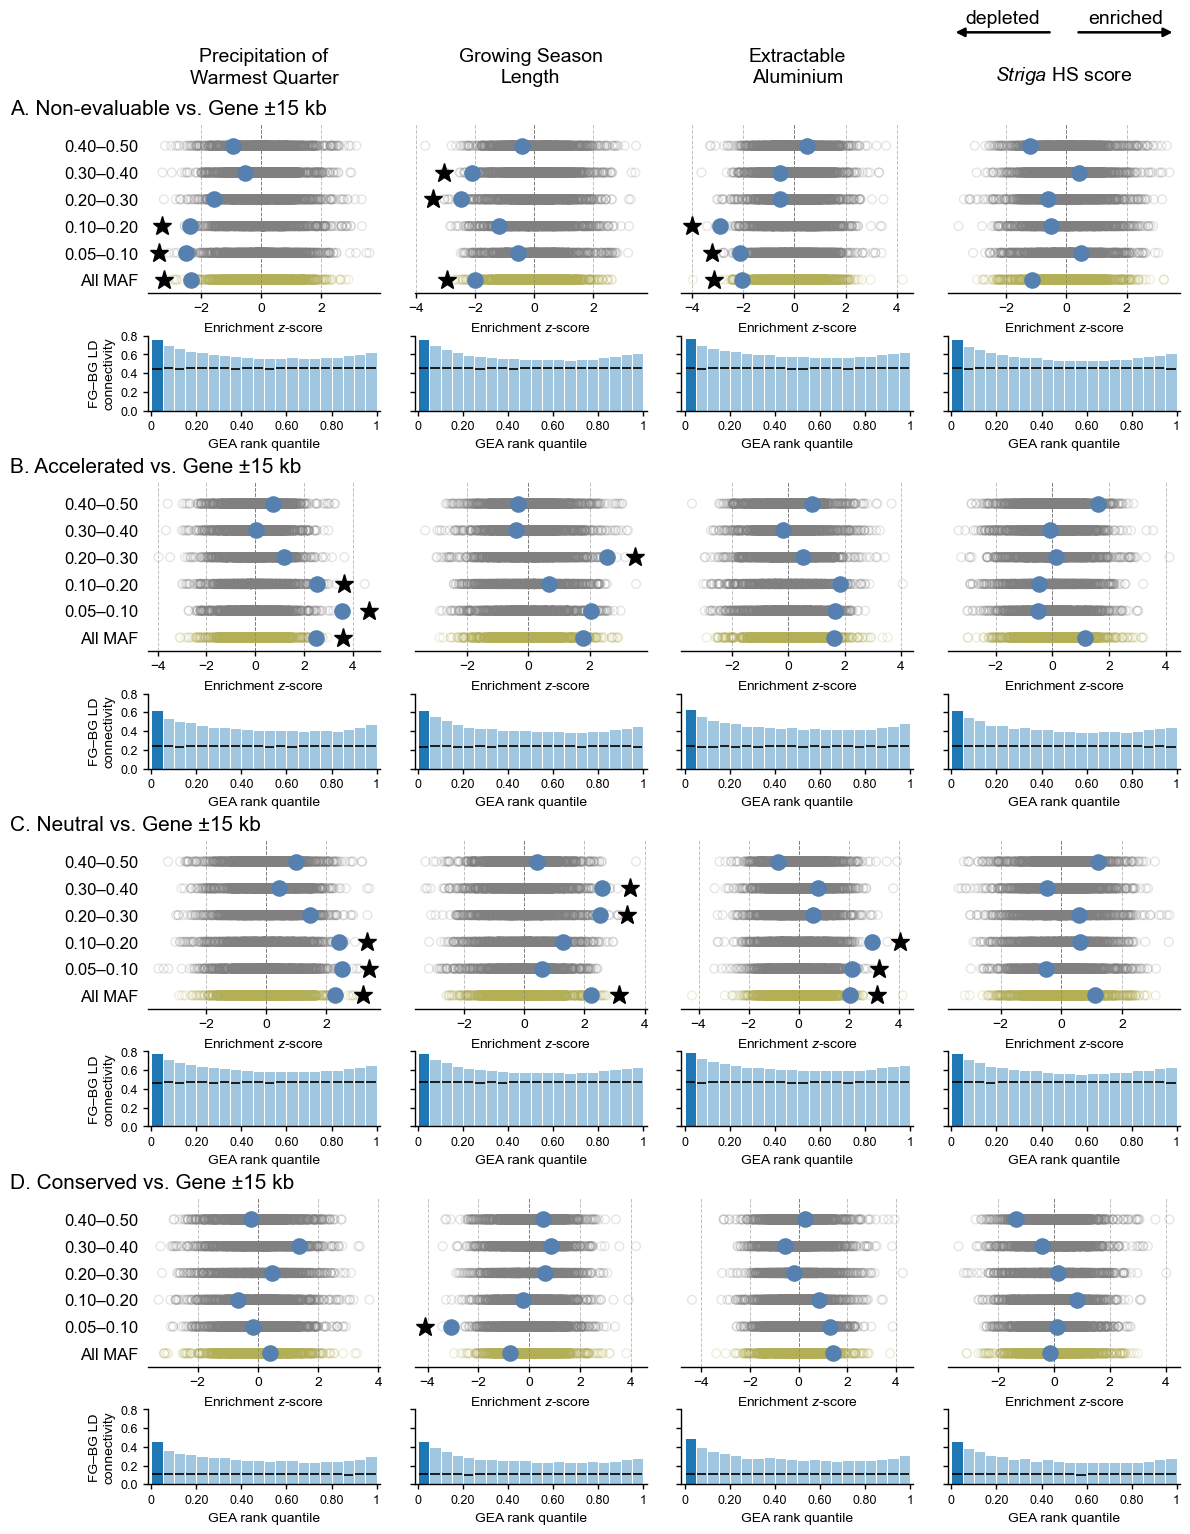

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/phylogenetic_conservation.enrichment_and_overlap.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/phylogenetic_conservation.enrichment_and_overlap.png', 'enrichment_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/phylogenetic_conservation.enrichment_and_overlap.enrichment.csv.gz', 'ld_overlap_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/phylogenetic_conservation.enrichment_and_overlap.ld_overlap.csv.gz'}


In [80]:
conservation_plot = plot_enrichment_section(
    conservation_result_files, conservation_contrast_labels, env_id_list,
    env_metadata_df, stratify_label_map, conservation_figure_prefix,
    figsize=(12, 15.2), block_gap=0.25, section_title_fontsize=15,
    panel_params=dict(wspace=0.15, hspace=0.35),
    letter_labels=True, env_titles_first_only=True,
)
plt.show()
print(conservation_plot['files'])


**图 9. 不同系统发育保守性类别中的 GEA 富集。** 各组依次比较不可评估、加速、中性和保守变异与基因及两侧各 15 kb 内的其余变异。上方面板展示四个重点环境变量中不同 MAF 分层下的 GEA 富集。观测富集值（蓝色）与 1,000 次染色体内标签循环置换得到的零分布均以 Z-score 展示。置换值以灰色表示，合并 MAF 组以橄榄色表示。星号表示相对于零分布的显著差异（双侧经验 P <0.05）。下方面板展示前景与背景其余变异在对应的 5% 宽度 GEA 排名区间内的 LD 连通性。深蓝色柱表示前景与背景中各自 GEA 信号最强的 5% 变异之间的 LD 连通性，浅蓝色柱表示其余排名区间，黑色水平线段表示打乱 GEA 分数后得到的参照值。



### 1.7 次要等位基因频率

使用 MAF ≥0.05 的全基因组变异，在基因及两侧各 15 kb 内，将五个 MAF 类别分别与其余变异比较。



In [81]:
from src.enrich import plot_set_enrichment

maf_contrast_labels = [
    ('maf_0.05_0.1', '0.05–0.10'),
    ('maf_0.1_0.2', '0.10–0.20'),
    ('maf_0.2_0.3', '0.20–0.30'),
    ('maf_0.3_0.4', '0.30–0.40'),
    ('maf_0.4_0.5', '0.40–0.50'),
]
maf_result_files = {
    contrast_id: f'{la_enrich_dir}/{contrast_id}.enrichment.json.gz'
    for contrast_id, _ in maf_contrast_labels
}
maf_figure_prefix = f'{la_enrich_dir}/minor_allele_frequency.enrichment'


In [82]:
stage_start = perf_counter()
for contrast_id, label in tqdm(maf_contrast_labels, desc='MAF enrichment'):
    contrast = dict(contrasts_settings[contrast_id])
    contrast['maf_stratify'] = ['all']
    site_contrast_runner(
        contrast_id, contrast, datasets[contrast['dataset']], env_id_list, la_enrich_dir,
        permutations=permutations, top_percent=top_percent, pool_num=pool_num,
        force_recompute=force_recompute,
    )
print(f'[{datetime.now():%H:%M:%S}] MAF comparisons ready ({perf_counter() - stage_start:.1f}s)')


MAF enrichment: 100%|██████████| 5/5 [00:00<00:00, 89.18it/s]

Enrichment results already exist for contrast maf_0.05_0.1, skipping.
Enrichment results already exist for contrast maf_0.1_0.2, skipping.
Enrichment results already exist for contrast maf_0.2_0.3, skipping.
Enrichment results already exist for contrast maf_0.3_0.4, skipping.
Enrichment results already exist for contrast maf_0.4_0.5, skipping.
[01:49:33] MAF comparisons ready (0.1s)


展示 MAF 相关富集



Figure and plot data: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/minor_allele_frequency.enrichment.{pdf,png,csv.gz}


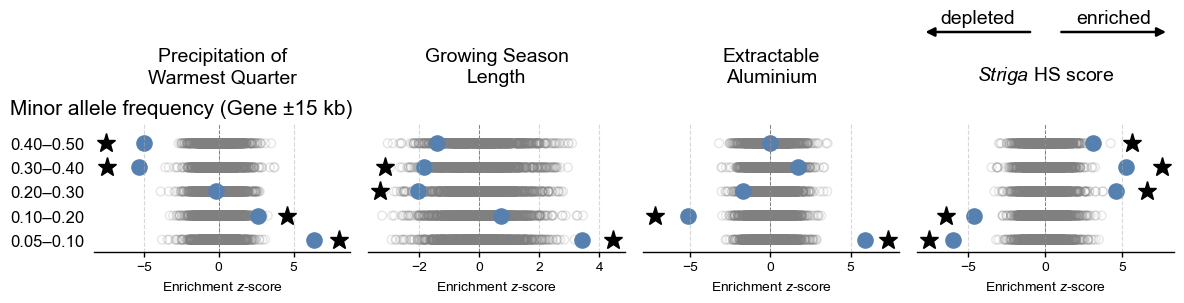

In [83]:
maf_results = {}
for contrast_id, _ in maf_contrast_labels:
    with gzip.open(maf_result_files[contrast_id], 'rt') as handle:
        maf_results[contrast_id] = json.load(handle)

maf_fig, maf_axes = plot_set_enrichment(
    maf_results, env_id_list, env_metadata_df, maf_contrast_labels,
    figsize=(12, 3.2), figure_title='Minor allele frequency (Gene ±15 kb)', figure_title_fontsize=15,
    figure_title_position='below_environments', enrichment_direction=True,
    xlabel=r'Enrichment $z$-score', xlabel_fontsize=10, tick_fontsize=10,
    set_tick_fontsize=12, title_fontsize=14,
    output_prefix=maf_figure_prefix, apply_style=False, show=False,
)
plt.show()


**图 10. 不同次要等位基因频率类别中的 GEA 富集。** 各行从下至上依次为 0.05–0.10 至 0.40–0.50 的 MAF 类别，各列对应四个重点环境变量。各类别与基因及两侧各 15 kb 内的其余变异比较。观测值（蓝色）与 1,000 次染色体内标签循环置换得到的零分布（灰色空心点）均以 Z-score 展示，星号表示相对于零分布的显著差异（双侧经验 P <0.05）。



### 1.8 核苷酸多样性

在基因及两侧各 15 kb 内，比较低（<Q25）、中（Q25 至 Q75 以下）、高（≥Q75）核苷酸多样性（π）类别中的 GEA 信号。在合并后的基因邻域内以 500 bp 窗口计算 π，不额外进行 MAF 筛选，保留至少含三条变异记录的窗口。

In [84]:
diversity_contrast_labels = [
    ('low_pi', 'Low π vs. Gene ±15 kb'),
    ('med_pi', 'Intermediate π vs. Gene ±15 kb'),
    ('high_pi', 'High π vs. Gene ±15 kb'),
]
diversity_result_files = {
    contrast_id: {
        'enrichment': f'{la_enrich_dir}/{contrast_id}.enrichment.json.gz',
        'overlap': f'{la_enrich_dir}/{contrast_id}_overlap_results.pkl',
    }
    for contrast_id, _ in diversity_contrast_labels
}
diversity_figure_prefix = f'{la_enrich_dir}/nucleotide_diversity.enrichment_and_overlap'


In [85]:
stage_start = perf_counter()
for contrast_id, label in tqdm(diversity_contrast_labels, desc='Nucleotide diversity'):
    contrast = contrasts_settings[contrast_id]
    context_df = datasets[contrast['dataset']]
    site_contrast_runner(
        contrast_id, contrast, context_df, env_id_list, la_enrich_dir,
        permutations=permutations, top_percent=top_percent, pool_num=pool_num,
        force_recompute=force_recompute,
    )
    calculate_contrast_ld_overlap(
        contrast_id, contrast, context_df, env_id_list, ld_dict[contrast['dataset']],
        la_enrich_dir, bin_width=bin_width, min_R2=min_r2, random_seed=random_seed,
        force_recompute=force_recompute,
    )
print(f'[{datetime.now():%H:%M:%S}] Diversity comparisons ready ({perf_counter() - stage_start:.1f}s)')


Nucleotide diversity: 100%|██████████| 3/3 [00:00<00:00, 54.06it/s]

Enrichment results already exist for contrast low_pi, skipping.
LD overlap results already exist for contrast low_pi. Skipping calculation.
Enrichment results already exist for contrast med_pi, skipping.
LD overlap results already exist for contrast med_pi. Skipping calculation.
Enrichment results already exist for contrast high_pi, skipping.
LD overlap results already exist for contrast high_pi. Skipping calculation.
[01:49:38] Diversity comparisons ready (0.1s)


展示多样性相关富集



2026-10-15 01:49:38 Plotting 3 enrichment contrasts


Enrichment panels: 100%|██████████| 3/3 [00:01<00:00,  2.81it/s]


2026-10-15 01:49:48 Saved /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/nucleotide_diversity.enrichment_and_overlap


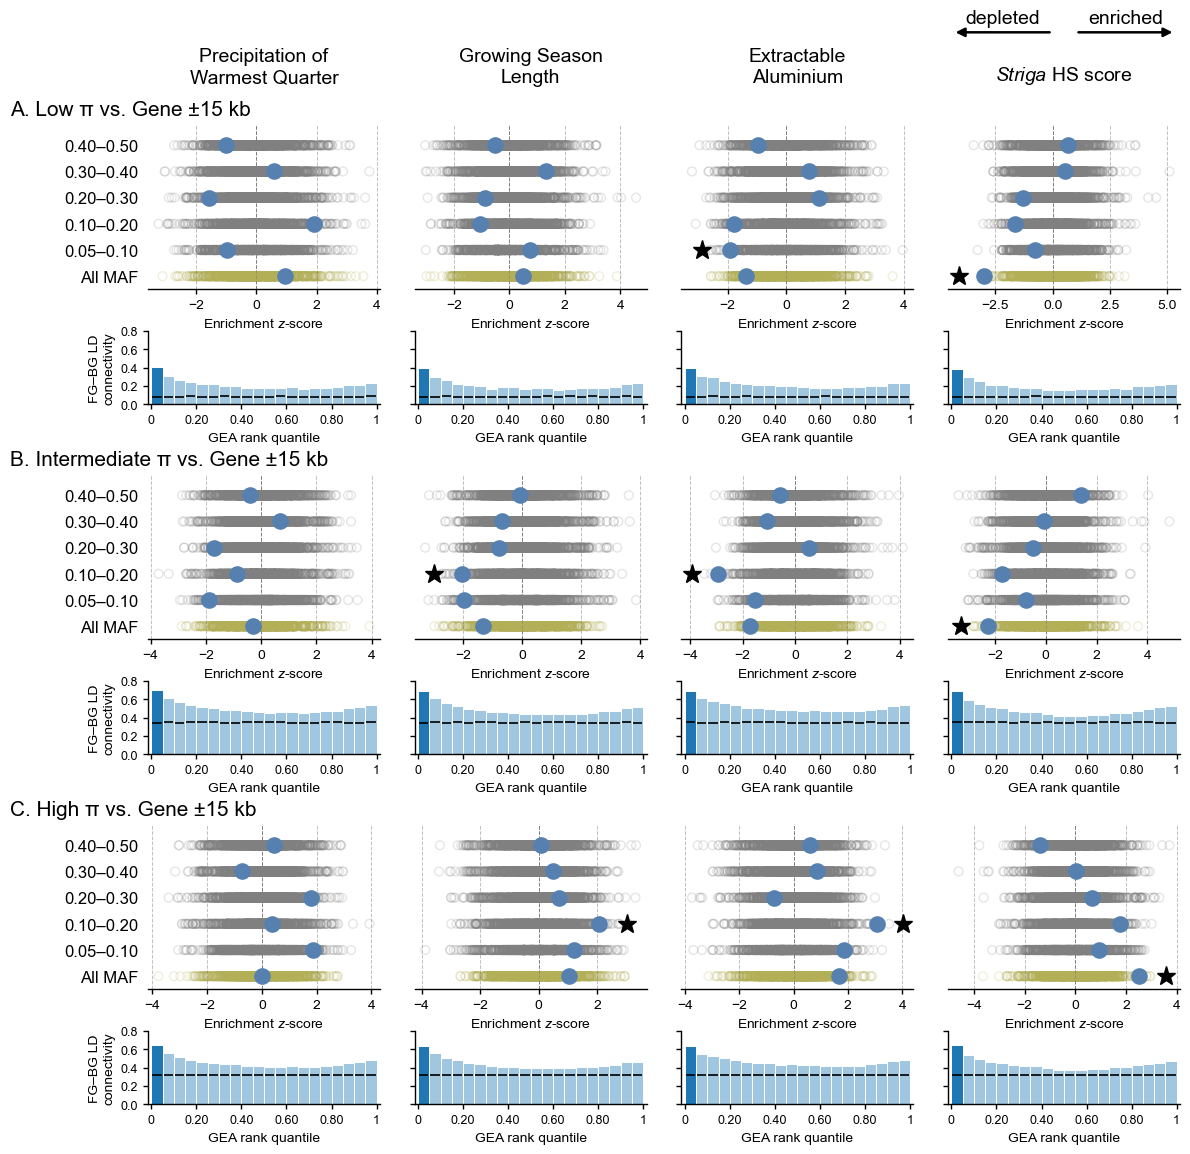

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/nucleotide_diversity.enrichment_and_overlap.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/nucleotide_diversity.enrichment_and_overlap.png', 'enrichment_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/nucleotide_diversity.enrichment_and_overlap.enrichment.csv.gz', 'ld_overlap_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/nucleotide_diversity.enrichment_and_overlap.ld_overlap.csv.gz'}


In [86]:
diversity_plot = plot_enrichment_section(
    diversity_result_files, diversity_contrast_labels, env_id_list,
    env_metadata_df, stratify_label_map, diversity_figure_prefix,
    figsize=(12, 11.4), block_gap=0.25, section_title_fontsize=15,
    panel_params=dict(wspace=0.15, hspace=0.35),
    letter_labels=True, env_titles_first_only=True,
)
plt.show()
print(diversity_plot['files'])


**图 11. 不同核苷酸多样性类别中的 GEA 富集。** 各组依次比较低、中、高 π 类别与基因及两侧各 15 kb 内的其余变异。上方面板展示四个重点环境变量中不同 MAF 分层下的 GEA 富集。观测富集值（蓝色）与 1,000 次染色体内标签循环置换得到的零分布均以 Z-score 展示。置换值以灰色表示，合并 MAF 组以橄榄色表示。星号表示相对于零分布的显著差异（双侧经验 P <0.05）。下方面板展示前景与背景其余变异在对应的 5% 宽度 GEA 排名区间内的 LD 连通性。深蓝色柱表示前景与背景中各自 GEA 信号最强的 5% 变异之间的 LD 连通性，浅蓝色柱表示其余排名区间，黑色水平线段表示打乱 GEA 分数后得到的参照值。



### 1.9 Proximal 区域的组成成分

在 Proximal 区域（基因及两侧各 5 kb）内，比较 ACR − TE 与 TE − ACR、ACR − UMR 与 UMR − ACR，以及 UMR − TE 与 TE − UMR。各两两对比排除当前两类共有的位点。另将 ACR ∪ UMR ∪ TE 并集与 Proximal 中的其余变异比较，考察合并覆盖区域的信号。



In [87]:
from src.enrich import summarize_site_contrasts

proximal_contrast_labels = [
    ('proximal_ACR_not_TE_vs_proximal_TE_not_ACR', 'ACR − TE vs. TE − ACR (Proximal)'),
    ('proximal_ACR_not_UMR_vs_proximal_UMR_not_ACR', 'ACR − UMR vs. UMR − ACR (Proximal)'),
    ('proximal_UMR_not_TE_vs_proximal_TE_not_UMR', 'UMR − TE vs. TE − UMR (Proximal)'),
    ('proximal_ACR_TE_UMR_vs_proximal', r'ACR $\cup$ UMR $\cup$ TE vs. Remaining Proximal'),
]
with open(f'{project_dir}/config/contrasts_settings.json') as handle:
    contrasts_settings = json.load(handle)
proximal_result_files = {
    contrast_id: {
        'enrichment': f'{la_enrich_dir}/{contrast_id}.enrichment.json.gz',
        'overlap': f'{la_enrich_dir}/{contrast_id}_overlap_results.pkl',
    }
    for contrast_id, _ in proximal_contrast_labels
}
proximal_figure_prefix = f'{la_enrich_dir}/proximal_components.enrichment_and_overlap'
site_counts_csv = f'{la_enrich_dir}/proximal_components.site_counts.csv.gz'


In [88]:
site_counts = summarize_site_contrasts(
    datasets['genome'], contrasts_settings,
    [contrast_id for contrast_id, _ in proximal_contrast_labels], site_counts_csv,
)
site_counts.loc[site_counts['STRATUM'] == 'all',
                ['CONTRAST', 'N_FOREGROUND', 'N_BACKGROUND', 'N_TESTED']]


[01:49:55] Summarizing contrast site counts


Contrast site counts: 100%|██████████| 4/4 [00:01<00:00,  3.12it/s]


,CONTRAST,N_FOREGROUND,N_BACKGROUND,N_TESTED
0,proximal_ACR_not_TE_vs_proximal_TE_not_ACR,87332,1011487,1098819
6,proximal_ACR_not_UMR_vs_proximal_UMR_not_ACR,22522,1069151,1091673
12,proximal_UMR_not_TE_vs_proximal_TE_not_UMR,1074070,951596,2025666
18,proximal_ACR_TE_UMR_vs_proximal,2109139,968031,3077170


In [89]:
if (site_counts[['N_FOREGROUND', 'N_BACKGROUND']] == 0).any().any():
    raise ValueError('A comparison or MAF stratum has an empty group; inspect site_counts before computing enrichment.')

stage_start = perf_counter()
for contrast_id, label in tqdm(proximal_contrast_labels, desc='Proximal components'):
    contrast = contrasts_settings[contrast_id]
    context_df = datasets[contrast['dataset']]
    site_contrast_runner(
        contrast_id, contrast, context_df, env_id_list, la_enrich_dir,
        permutations=permutations, top_percent=top_percent, pool_num=pool_num,
        force_recompute=force_recompute,
    )
    calculate_contrast_ld_overlap(
        contrast_id, contrast, context_df, env_id_list, ld_dict[contrast['dataset']],
        la_enrich_dir, bin_width=bin_width, min_R2=min_r2, random_seed=random_seed,
        force_recompute=force_recompute,
    )
print(f'[{datetime.now():%H:%M:%S}] Proximal comparisons ready ({perf_counter() - stage_start:.1f}s)')


Proximal components: 100%|██████████| 4/4 [00:00<00:00, 53.91it/s]

Enrichment results already exist for contrast proximal_ACR_not_TE_vs_proximal_TE_not_ACR, skipping.
LD overlap results already exist for contrast proximal_ACR_not_TE_vs_proximal_TE_not_ACR. Skipping calculation.
Enrichment results already exist for contrast proximal_ACR_not_UMR_vs_proximal_UMR_not_ACR, skipping.
LD overlap results already exist for contrast proximal_ACR_not_UMR_vs_proximal_UMR_not_ACR. Skipping calculation.
Enrichment results already exist for contrast proximal_UMR_not_TE_vs_proximal_TE_not_UMR, skipping.
LD overlap results already exist for contrast proximal_UMR_not_TE_vs_proximal_TE_not_UMR. Skipping calculation.
Enrichment results already exist for contrast proximal_ACR_TE_UMR_vs_proximal, skipping.
LD overlap results already exist for contrast proximal_ACR_TE_UMR_vs_proximal. Skipping calculation.
[01:49:57] Proximal comparisons ready (0.1s)


展示 Proximal 成分对比



2026-10-15 01:49:57 Plotting 4 enrichment contrasts


Enrichment panels: 100%|██████████| 4/4 [00:01<00:00,  2.88it/s]
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


2026-10-15 01:50:09 Saved /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/proximal_components.enrichment_and_overlap


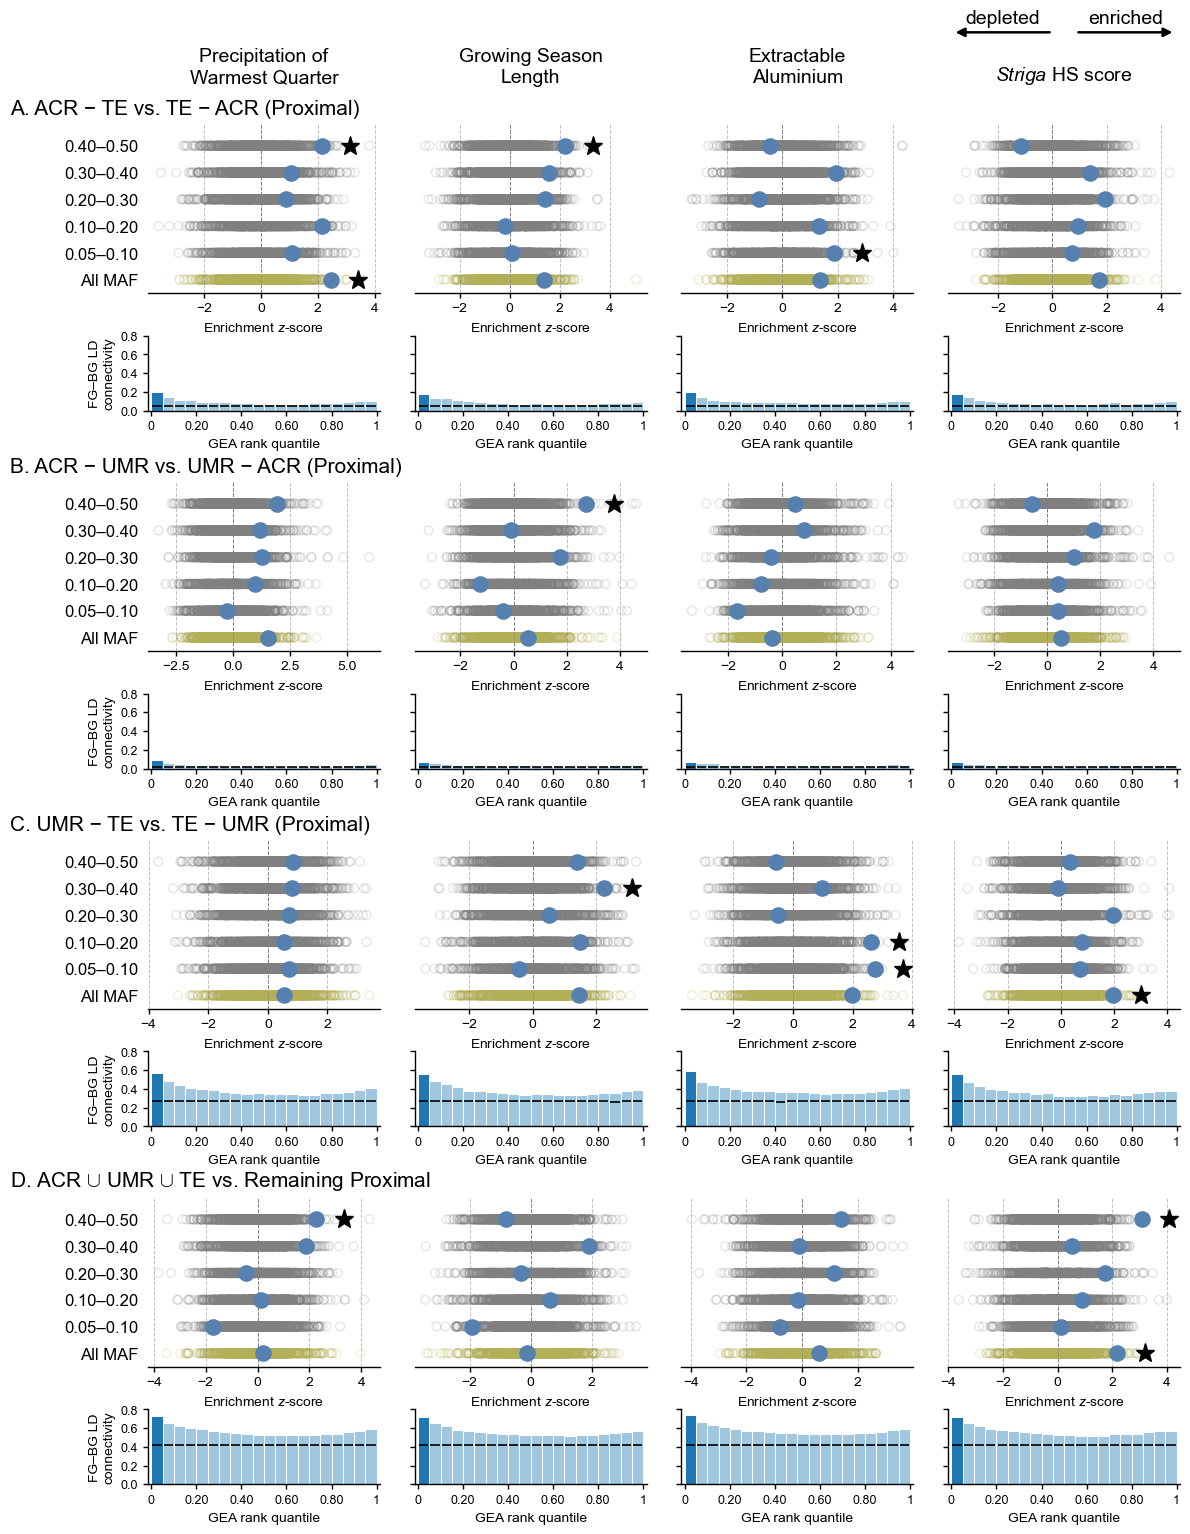

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/proximal_components.enrichment_and_overlap.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/proximal_components.enrichment_and_overlap.png', 'enrichment_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/proximal_components.enrichment_and_overlap.enrichment.csv.gz', 'ld_overlap_csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/proximal_components.enrichment_and_overlap.ld_overlap.csv.gz'}


In [90]:
proximal_plot = plot_enrichment_section(
    proximal_result_files, proximal_contrast_labels, env_id_list,
    env_metadata_df, stratify_label_map, proximal_figure_prefix,
    figsize=(12, 15.2), block_gap=0.25, section_title_fontsize=15,
    panel_params=dict(wspace=0.15, hspace=0.35),
    letter_labels=True, env_titles_first_only=True,
)
plt.show()
print(proximal_plot['files'])


**图 12. Proximal 区域不同组成成分中的 GEA 富集。** 各组依次比较 ACR − TE 与 TE − ACR、ACR − UMR 与 UMR − ACR、UMR − TE 与 TE − UMR，以及 ACR ∪ UMR ∪ TE 并集与 Proximal 中的其余变异。上方面板展示四个重点环境变量中不同 MAF 分层下的 GEA 富集。观测富集值（蓝色）与 1,000 次染色体内标签循环置换得到的零分布均以 Z-score 展示。置换值以灰色表示，合并 MAF 组以橄榄色表示。星号表示相对于零分布的显著差异（双侧经验 P <0.05）。下方面板展示前景与背景其余变异在对应的 5% 宽度 GEA 排名区间内的 LD 连通性。深蓝色柱表示前景与背景中各自 GEA 信号最强的 5% 变异之间的 LD 连通性，浅蓝色柱表示其余排名区间，黑色水平线段表示打乱 GEA 分数后得到的参照值。



### 1.10 基因级 GEA 富集

比较表达、共表达网络、拷贝冗余和重组率类别与 GEA 信号最强的前 5% 基因之间的重叠。



In [91]:
from src.enrich import gene_contrast_runner, plot_set_enrichment_section

gene_group_labels = [
    ('expression', 'Gene expression'),
    ('network', 'Gene co-expression networks'),
    ('copy', 'Gene copy redundancy'),
    ('recombination', 'Recombination rate'),
]
gene_set_labels = {
    'expression': [
        ('no_expression_genes', 'No detected expression'),
        ('high_variance_genes', 'High expression variability'),
        ('stably_expressed_genes', 'Stable expression'),
    ],
    'network': [
        ('non_module_genes', 'Non-module genes'),
        ('module_genes', 'Non-hub module genes'),
        ('module_hub_genes', 'Module hubs'),
    ],
    'copy': [
        ('single_copy_genes', 'Single-copy genes'),
        ('multi_copy_genes', 'Multiple-copy genes'),
        ('orphan_genes', 'Orphan genes'),
    ],
    'recombination': [
        ('low_recombination_genes', 'Low recombination'),
        ('med_recombination_genes', 'Intermediate recombination'),
        ('high_recombination_genes', 'High recombination'),
    ],
}
gene_result_files = {
    contrast_id: f'{la_enrich_dir}/{contrast_id}.enrichment.json.gz'
    for labels in gene_set_labels.values()
    for contrast_id, _ in labels
}
gene_figure_prefix = f'{la_enrich_dir}/gene_level_features.enrichment'


#### 1.10.1 基因表达

以 TPM >2 定义有效表达，所有样本均无有效表达的基因归为未检测到表达。相对于 LOWESS 均值–方差关系，标准化残差 >1 的基因归为高变异，残差 <1 且所有样本均有有效表达的基因归为稳定表达。


In [92]:
stage_start = perf_counter()
for contrast_id, label in tqdm(gene_set_labels['expression'], desc='Gene expression'):
    contrast = contrasts_settings[contrast_id]
    gene_contrast_runner(
        contrast_id, contrast, datasets[contrast['dataset']], env_id_list, la_enrich_dir,
        permutations=permutations, top_percent=top_percent, seed=random_seed,
        force_recompute=force_recompute,
    )
print(f'[{datetime.now():%H:%M:%S}] Gene expression results ready ({perf_counter() - stage_start:.1f}s)')


Gene expression: 100%|██████████| 3/3 [00:00<00:00, 131.67it/s]

Enrichment results already exist for contrast no_expression_genes, skipping.
Enrichment results already exist for contrast high_variance_genes, skipping.
Enrichment results already exist for contrast stably_expressed_genes, skipping.
[01:50:15] Gene expression results ready (0.0s)


#### 1.10.2 基因共表达网络

比较共表达模块外基因、模块中的非枢纽成员和模块枢纽基因。三类互不重叠，枢纽依据模块内连接程度和中心性定义。



In [93]:
stage_start = perf_counter()
for contrast_id, label in tqdm(gene_set_labels['network'], desc='Gene co-expression networks'):
    contrast = contrasts_settings[contrast_id]
    gene_contrast_runner(
        contrast_id, contrast, datasets[contrast['dataset']], env_id_list, la_enrich_dir,
        permutations=permutations, top_percent=top_percent, seed=random_seed,
        force_recompute=force_recompute,
    )
print(f'[{datetime.now():%H:%M:%S}] Gene co-expression networks results ready ({perf_counter() - stage_start:.1f}s)')


Gene co-expression networks: 100%|██████████| 3/3 [00:00<00:00, 85.44it/s]

Enrichment results already exist for contrast non_module_genes, skipping.
Enrichment results already exist for contrast module_genes, skipping.
Enrichment results already exist for contrast module_hub_genes, skipping.
[01:50:15] Gene co-expression networks results ready (0.0s)


#### 1.10.3 基因拷贝冗余

比较禾本科层级直系同源组中的单拷贝、多拷贝基因，以及未获得直系同源组分配的 orphan 基因。



In [94]:
stage_start = perf_counter()
for contrast_id, label in tqdm(gene_set_labels['copy'], desc='Gene copy redundancy'):
    contrast = contrasts_settings[contrast_id]
    gene_contrast_runner(
        contrast_id, contrast, datasets[contrast['dataset']], env_id_list, la_enrich_dir,
        permutations=permutations, top_percent=top_percent, seed=random_seed,
        force_recompute=force_recompute,
    )
print(f'[{datetime.now():%H:%M:%S}] Gene copy redundancy results ready ({perf_counter() - stage_start:.1f}s)')


Gene copy redundancy: 100%|██████████| 3/3 [00:00<00:00, 140.02it/s]

Enrichment results already exist for contrast single_copy_genes, skipping.
Enrichment results already exist for contrast multi_copy_genes, skipping.
Enrichment results already exist for contrast orphan_genes, skipping.
[01:50:16] Gene copy redundancy results ready (0.0s)


#### 1.10.4 重组率

依据 Q25 和 Q75 比较低、中、高基因重组率类别。基因重组率为重叠图谱区间的均值。



In [95]:
stage_start = perf_counter()
for contrast_id, label in tqdm(gene_set_labels['recombination'], desc='Recombination rate'):
    contrast = contrasts_settings[contrast_id]
    gene_contrast_runner(
        contrast_id, contrast, datasets[contrast['dataset']], env_id_list, la_enrich_dir,
        permutations=permutations, top_percent=top_percent, seed=random_seed,
        force_recompute=force_recompute,
    )
print(f'[{datetime.now():%H:%M:%S}] Recombination rate results ready ({perf_counter() - stage_start:.1f}s)')


Recombination rate: 100%|██████████| 3/3 [00:00<00:00, 136.64it/s]

Enrichment results already exist for contrast low_recombination_genes, skipping.
Enrichment results already exist for contrast med_recombination_genes, skipping.
Enrichment results already exist for contrast high_recombination_genes, skipping.
[01:50:16] Recombination rate results ready (0.0s)


展示基因级富集



[01:50:16] Plotting grouped enrichment sets


Enrichment groups: 100%|██████████| 4/4 [00:00<00:00,  7.45it/s]


[01:50:22] Saved /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/gene_level_features.enrichment


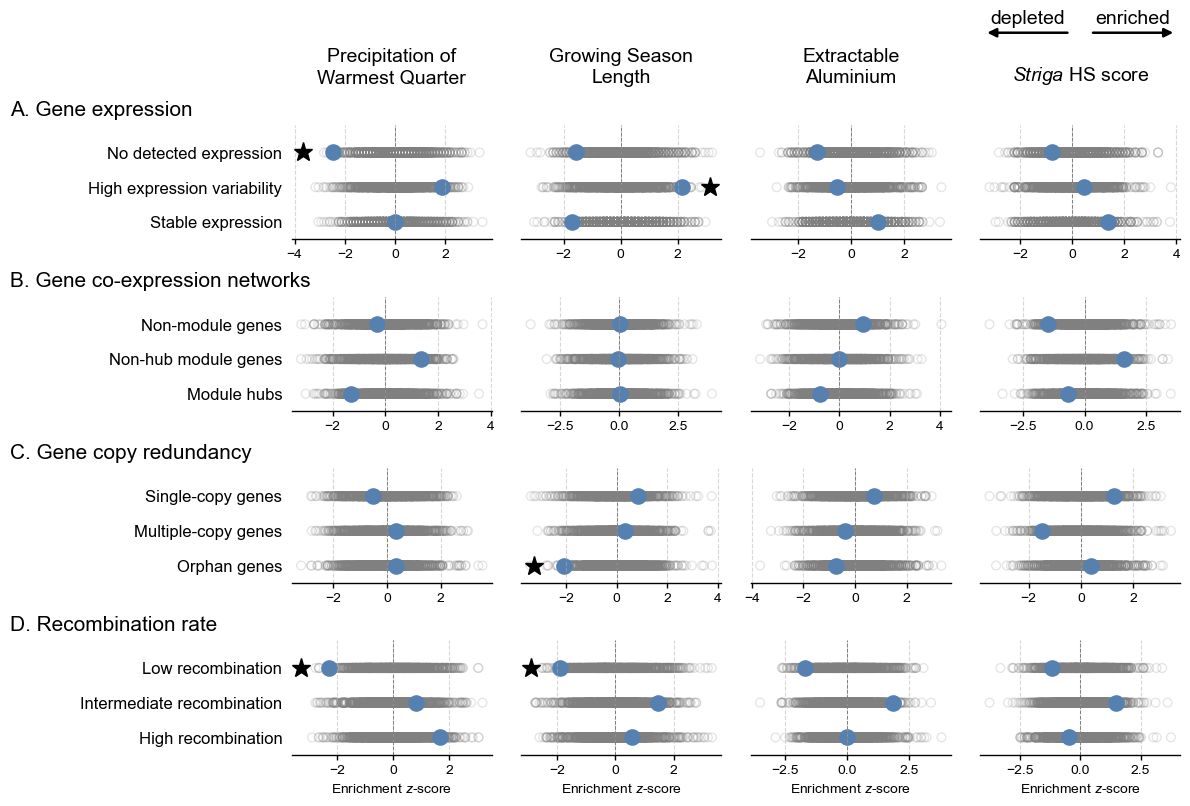

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/gene_level_features.enrichment.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/gene_level_features.enrichment.png', 'csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/gene_level_features.enrichment.csv.gz'}


In [96]:
gene_plot = plot_set_enrichment_section(
    gene_result_files, gene_group_labels, gene_set_labels,
    env_id_list, env_metadata_df, gene_figure_prefix,
    figsize=(12, 8), block_gap=0.5, section_title_fontsize=15,
    value_column='JACCARD',
    panel_params=dict(tick_fontsize=10, set_tick_fontsize=12, title_fontsize=14),
)
plt.show()
print(gene_plot['files'])


**图 13. 不同基因属性中的 GEA 富集。** 各组依次展示基因表达、共表达网络、拷贝冗余和重组率，各行代表基因类别，各列对应四个重点环境变量。观测值为各类别与 GEA 信号最强的前 5% 基因之间的 Jaccard 指数。观测值（蓝色）与 1,000 次染色体内标签循环置换得到的零分布（灰色空心点）均以 Z-score 展示，星号表示相对于零分布的显著差异（双侧经验 P <0.05）。



### 1.11 绘制论文主图

汇总前述基因组注释与基因属性的富集结果，绘制论文主图。



In [97]:
from src.enrich import plot_set_enrichment_section

main_group_labels = [
    ('compartments', 'Genomic compartments'),
    ('expression', 'Gene expression'),
    ('structure', 'Gene Structure'),
    ('coding', 'Coding Mutations'),
    ('ACRs', 'Accessible chromatin regions'),
    ('UMRs', 'Unmethylated regions'),
    ('network', 'Gene regulatory network'),
    ('copy', 'Gene copy redundancy'),
    ('ribo', 'riboSNitches'),
]
# Rows are ordered from top to bottom within each group.
main_set_labels = {
    'compartments': [
        ('TE_vs_genome', 'TE vs. Genome'),
        ('distal_TE_vs_distal', 'Distal TEs vs. Distal'),
        ('other_intergenic_vs_genome', 'Other intergenic vs. Genome'),
        ('proximal_TE_vs_proximal', 'Proximal TEs vs. Proximal'),
        ('genic_2kb_vs_genome', 'Genic vs. Genome'),
    ],
    'expression': [
        ('no_expression_genes', 'Genes with no detected expr.'),
        ('high_variance_genes', 'Genes with high var. expr.'),
        ('stably_expressed_genes', 'Genes with stable expr.'),
    ],
    'structure': [
        ('upstream_2kb_vs_genic', 'Upstream (2 kb) vs. Genic'),
        ('five_prime_UTR_vs_genic', "5′ UTR vs. Genic"),
        ('CDS_vs_genic', 'CDS vs. Genic'),
        ('intron_vs_genic', 'Intron vs. Genic'),
        ('three_prime_UTR_vs_genic', "3′ UTR vs. Genic"),
        ('downstream_2kb_vs_genic', 'Downstream (2 kb) vs. Genic'),
    ],
    'coding': [
        ('synonymous_vs_CDS', 'Synonymous vs. CDS'),
        ('missense_vs_CDS', 'Missense vs. CDS'),
        ('putative_LoF_vs_CDS', 'Putative loss-of-function vs. CDS'),
    ],
    'ACRs': [
        ('ACR_vs_genome', 'ACRs vs. Genome'),
        ('distal_ACR_vs_distal', 'Distal ACRs vs. Distal'),
        ('proximal_ACR_vs_proximal', 'Proximal ACRs vs. Proximal'),
    ],
    'UMRs': [
        ('UMR_vs_genome', 'UMRs vs. Genome'),
        ('distal_UMR_vs_distal', 'Distal UMRs vs. Distal'),
        ('proximal_UMR_vs_proximal', 'Proximal UMRs vs. Proximal'),
    ],
    'network': [
        ('non_module_genes', 'Non-module genes'),
        ('module_genes', 'Module genes'),
        ('module_hub_genes', 'Module hubs'),
    ],
    'copy': [
        ('orphan_genes', 'Orphan genes'),
        ('multi_copy_genes', 'Multi-copy genes'),
        ('single_copy_genes', 'Single-copy genes'),
    ],
    'ribo': [('riboSNitch_vs_gene_body', 'riboSNitches vs. Gene body')],
}
main_result_files = {
    contrast_id: f'{la_enrich_dir}/{contrast_id}.enrichment.json.gz'
    for labels in main_set_labels.values()
    for contrast_id, _ in labels
}
main_statistic_columns = {
    group_id: 'JACCARD' if group_id in ['expression', 'network', 'copy'] else 'SCORE_RATIO'
    for group_id, _ in main_group_labels
}
hypothesis_groups = [
    dict(label='Classic molecular evolution hypotheses', color='#D95F02',
         group_ids=['compartments', 'expression', 'structure', 'coding']),
    dict(label='Functional genomics hypotheses', color='#A32B9A',
         group_ids=['ACRs', 'UMRs', 'network', 'copy', 'ribo']),
]
main_figure_prefix = f'{la_enrich_dir}/genomic_gene_features.main'


[01:50:25] Plotting grouped enrichment sets


Enrichment groups: 100%|██████████| 9/9 [00:02<00:00,  3.37it/s]


[01:50:39] Saved /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/genomic_gene_features.main


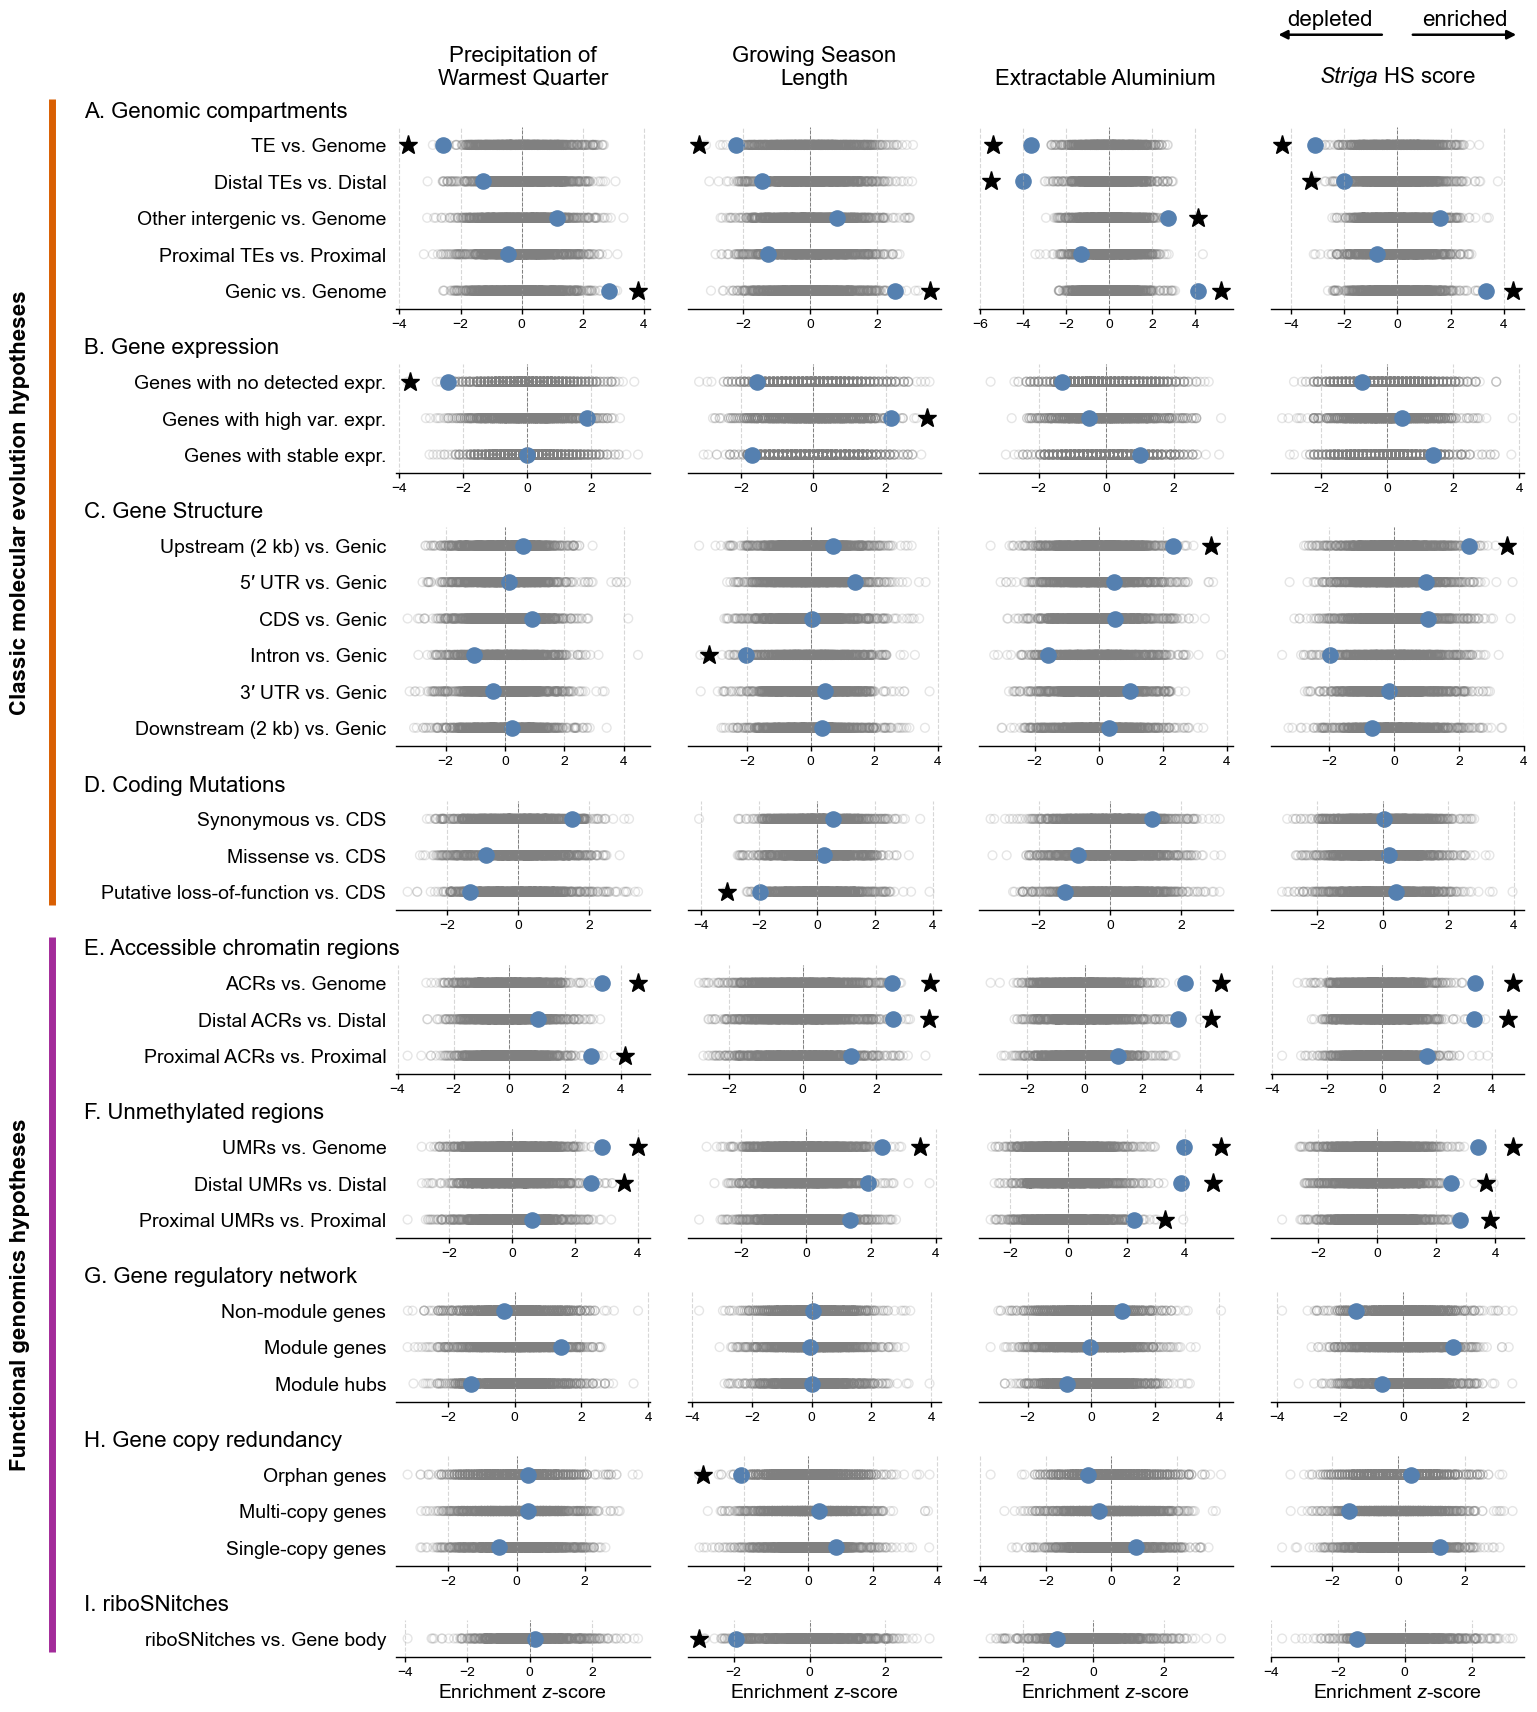

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/genomic_gene_features.main.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/genomic_gene_features.main.png', 'csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/local_adaptation/genomic_gene_features.main.csv.gz'}


In [98]:
main_plot = plot_set_enrichment_section(
    main_result_files, main_group_labels, main_set_labels,
    env_id_list, env_metadata_df, main_figure_prefix,
    figsize=(16, 17), block_gap=0.45, section_title_fontsize=16,
    left=0.285, heading_x=0.09,
    value_column=main_statistic_columns, hypothesis_groups=hypothesis_groups,
    hypothesis_line_x=0.07, hypothesis_label_x=0.05, hypothesis_fontsize=16,
    hypothesis_linewidth=5, hypothesis_bottom_offset=0.05, hypothesis_fontweight='bold',
    header_labels=[
        'Precipitation of\nWarmest Quarter', 'Growing Season\nLength',
        'Extractable Aluminium', 'Striga HS score',
    ],
    panel_params=dict(
        tick_fontsize=10, set_tick_fontsize=14, title_fontsize=16, xlabel_fontsize=14,
        perm_size=40, obs_size=120, star_size=14, wspace=0.15, symmetric_xlim=True,
        ylim_pad=(0.5, 0.5),
    ),
)
plt.show()
print(main_plot['files'])


**图 14. 不同功能变异类别中的 GEA 富集。** 关于局域适应变异所在区域与特征的假说分为“经典分子进化假说”（A-D）和“功能基因组学假说”（E-I）。富集检验针对 GEA 信号最强的前 5%。位点级分析的富集背景在“vs.”后标明，而基因级分析以全部基因为背景。观测值（蓝色）基于 1,000 次零假设置换（灰色）计算为 z-score，星号表示显著富集（双侧经验 P<0.05）。



## 2. 低多样性区域与稀有变异

考察不同基因结构和不同编码区效应的变异在低多样性区域和稀有变异中是否富集。低多样性区域定义为 500 bp 窗口中 π 最低的 5%，稀有变异定义为 CDS 变异中 MAF 最低的 5%。



In [99]:
from src.enrich import prepare_low_tail_enrichment, plot_low_tail_enrichment

lower_fraction = 0.05
context_threshold = 0.75
permutations = 1000
force_recompute = False
window_contexts_h5 = f'{results_dir}/genome_windows_contexts.b500.h5'
cds_contexts_h5 = f'{results_dir}/site_contexts.cds.maf0.01.h5'
pi_enrich_dir = f'{enrich_dir}/consistent_selection'
maf_enrich_dir = f'{enrich_dir}/consistent_selection_site'
pi_summary_csv = f'{pi_enrich_dir}/gene_structure.low_pi.summary.csv.gz'
maf_summary_csv = f'{maf_enrich_dir}/coding_consequences.low_maf.summary.csv.gz'
figure_prefix = f'{enrich_dir}/low_diversity_and_rare_variants'
with open(f'{project_dir}/config/contrasts_settings.json') as handle:
    contrasts_settings = json.load(handle)

pi_labels = [
    ('upstream_2kb_vs_genic', 'Upstream 2 kb'),
    ('five_prime_UTR_vs_genic', "5′ UTR"),
    ('CDS_vs_genic', 'CDS'),
    ('intron_vs_genic', 'Intron'),
    ('three_prime_UTR_vs_genic', "3′ UTR"),
    ('downstream_2kb_vs_genic', 'Downstream 2 kb'),
]
maf_labels = [
    ('synonymous_vs_CDS', 'Synonymous'),
    ('missense_vs_CDS', 'Missense'),
    ('putative_LoF_vs_CDS', 'Putative loss-of-function'),
]
panels = [
    dict(trait_id='PI', title='Low-diversity regions',
         definition='Lowest 5% of π windows (500 bp)',
         background='Genic regions (gene bodies ±2 kb)', labels=pi_labels,
         result_files={key: f'{pi_enrich_dir}/{key}/{key}.enrichment.json.gz' for key, _ in pi_labels},
         summary_csv=pi_summary_csv),
    dict(trait_id='MAF', title='Rare variants',
         definition='Lowest 5% of MAF variants', background='CDS variants (MAF ≥0.01)',
         labels=maf_labels,
         result_files={key: f'{maf_enrich_dir}/{key}/{key}.enrichment.json.gz' for key, _ in maf_labels},
         summary_csv=maf_summary_csv),
]


### 2.1 低多样性区域

In [100]:
pi_summary = prepare_low_tail_enrichment(
    window_contexts_h5, contrasts_settings, [key for key, _ in pi_labels],
    'PI', pi_enrich_dir, pi_summary_csv,
    lower_fraction=lower_fraction, context_threshold=context_threshold,
    permutations=permutations, force_recompute=force_recompute,
)
pi_summary[['CONTRAST', 'THRESHOLD', 'N_FOREGROUND', 'FOREGROUND_LOW_FRACTION', 'RISK_RATIO', 'P_VALUE']]


[01:50:45] Preparing lower-tail PI enrichment


PI contrasts: 100%|██████████| 6/6 [00:00<00:00, 32.98it/s]

upstream_2kb_vs_genic: reuse /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/consistent_selection/upstream_2kb_vs_genic/upstream_2kb_vs_genic.enrichment.json.gz
five_prime_UTR_vs_genic: reuse /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/consistent_selection/five_prime_UTR_vs_genic/five_prime_UTR_vs_genic.enrichment.json.gz
CDS_vs_genic: reuse /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/consistent_selection/CDS_vs_genic/CDS_vs_genic.enrichment.json.gz
intron_vs_genic: reuse /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/consistent_selection/intron_vs_genic/intron_vs_genic.enrichment.json.gz
three_prime_UTR_vs_genic: reuse /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/consistent_selection/three_prime_UTR_vs_genic/three_pri

,CONTRAST,THRESHOLD,N_FOREGROUND,FOREGROUND_LOW_FRACTION,RISK_RATIO,P_VALUE
0,upstream_2kb_vs_genic,0.000239,103836,0.025608,0.431151,0.001998
1,five_prime_UTR_vs_genic,0.000239,5684,0.047502,0.949302,0.323676
2,CDS_vs_genic,0.000239,30305,0.083254,1.768971,0.001998
3,intron_vs_genic,0.000239,78118,0.065619,1.430571,0.001998
4,three_prime_UTR_vs_genic,0.000239,13419,0.052686,1.055844,0.273726
5,downstream_2kb_vs_genic,0.000239,100643,0.035661,0.644978,0.001998


### 2.2 稀有变异

In [101]:
maf_summary = prepare_low_tail_enrichment(
    cds_contexts_h5, contrasts_settings, [key for key, _ in maf_labels],
    'MAF', maf_enrich_dir, maf_summary_csv,
    lower_fraction=lower_fraction, permutations=permutations,
    force_recompute=force_recompute,
)
maf_summary[['CONTRAST', 'THRESHOLD', 'N_FOREGROUND', 'FOREGROUND_LOW_FRACTION', 'RISK_RATIO', 'P_VALUE']]


[01:50:48] Preparing lower-tail MAF enrichment


MAF contrasts: 100%|██████████| 3/3 [00:00<00:00, 69.00it/s]

synonymous_vs_CDS: reuse /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/consistent_selection_site/synonymous_vs_CDS/synonymous_vs_CDS.enrichment.json.gz
missense_vs_CDS: reuse /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/consistent_selection_site/missense_vs_CDS/missense_vs_CDS.enrichment.json.gz
putative_LoF_vs_CDS: reuse /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/consistent_selection_site/putative_LoF_vs_CDS/putative_LoF_vs_CDS.enrichment.json.gz


,CONTRAST,THRESHOLD,N_FOREGROUND,FOREGROUND_LOW_FRACTION,RISK_RATIO,P_VALUE
0,synonymous_vs_CDS,0.012415,174908,0.057316,0.794504,0.001998
1,missense_vs_CDS,0.012415,186477,0.071671,1.201699,0.001998
2,putative_LoF_vs_CDS,0.012415,12820,0.089080,1.378324,0.001998


[01:50:49] Plotting lower-tail enrichment


Lower-tail panels: 100%|██████████| 2/2 [00:00<00:00, 13.37it/s]


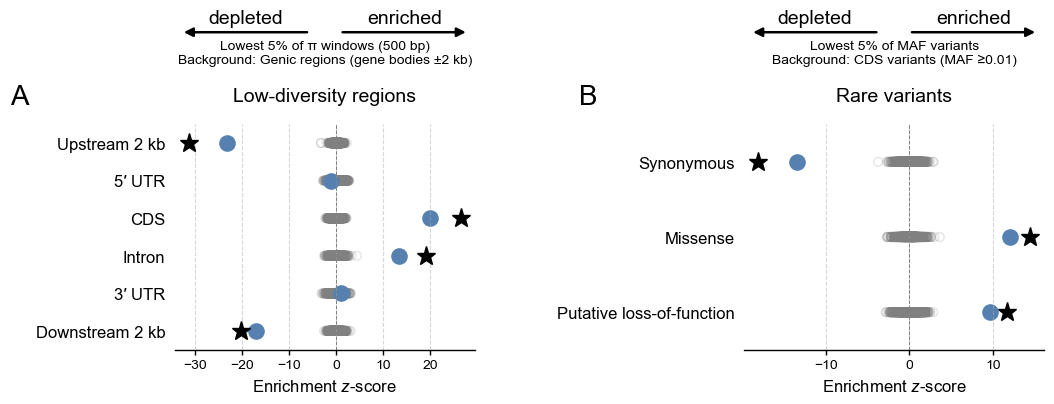

{'pdf': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/low_diversity_and_rare_variants.pdf', 'png': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/low_diversity_and_rare_variants.png', 'csv': '/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/enrichment/low_diversity_and_rare_variants.csv.gz'}


In [102]:
low_tail_plot = plot_low_tail_enrichment(
    panels, figure_prefix, figsize=(11, 5.5), wspace=0.9,
    title_fontsize=14, label_fontsize=12, tick_fontsize=10, panel_letter_fontsize=20,
)
plt.show()
print(low_tail_plot['files'])


**图 15. 低多样性区域与稀有变异中的注释富集。** （A）Genic 区域中 π 最低的 5% 的 500 bp 窗口内的基因结构类别。（B）CDS 变异中 MAF 最低的 5% 变异的编码后果类别。观测值为各类别与相应低 π 或低 MAF 集合之间的 Jaccard 重叠。观测值（蓝色）与 1,000 次染色体内标签循环置换得到的零分布（灰色空心点）均以 Z-score 展示，星号表示相对于零分布的显著差异（双侧经验 P <0.05）。

